# 🧠 SynthRAD2023: Model 2 — Paired Pix2Pix Conditional GAN
## Benchmark Paired Adversarial Image-to-Image Translation for Brain MRI-to-CT Synthesis
### Research Paper Comparative Study: Four Independent Models

This notebook implements **Model 2: Pix2Pix (Paired Conditional GAN)** in a rigorous, multi-model scientific study for synthetic CT (sCT) generation from brain MRI on the **SynthRAD2023 Task 1 Brain cohort (UMC Utrecht)**.

---

### 🔬 The Four Models in this Research Study:
1. **Model 1 — Supervised ResUNet Baseline:** Direct supervised regression using Residual U-Net trained with Masked $L_1$ + Masked SSIM loss (Completed; best validation checkpoint at **Epoch 75**).
2. **Model 2 — Paired Pix2Pix cGAN (This Notebook):** Canonical paired conditional GAN establishing an adversarial baseline with a U-Net Generator and PatchGAN Discriminator trained under adversarial + masked $L_1$ reconstruction loss.
3. **Model 3 — Conditional DDPM (CDDPM):** Conditional diffusion probabilistic model with a simpler/non-ResUNet denoiser (Planned).
4. **Model 4 — ResUNet-CDDPM (Proposed SOTA):** Historical Epoch-73 Residual U-Net-based conditional DDPM integrating attention gates and bone-weighted hybrid losses (**SSIM: $0.8963 \pm 0.0319$, PSNR: $24.35 \pm 2.38\text{ dB}$, HU-MAE: $57.4 \pm 18.8\text{ HU}$, Bone Dice: $0.7732 \pm 0.0696$**).

---

### 🛡️ Scientific Integrity & Protocol Standards:
- **Identical Dataset & Split:** Uses the exact 60-patient cohort (48 Train / 6 Val / 6 Test) locked to `SEED = 42`.
- **Zero Slice Leakage (Strict Patient Isolation):** Patient IDs are strictly disjoint across Train, Val, and Test.
- **Frozen Test Set:** The 6 held-out test patients (`1BA054`, `1BA097`, `1BA172`, `1BA234`, `1BA256`, `1BA307`, 363 slices) remain completely frozen and untouched during training and checkpoint selection.
- **Leakage-Free Preprocessing:** The anatomical head mask is derived **strictly from the input MRI** (Otsu-like threshold $> 15$, $7 \times 7$ morphological closing, filled largest contour). Zero target CT information is leaked to the generator.
- **Canonical Architecture:** Genuine paired Pix2Pix architecture: U-Net Generator with skip connections ($1 \to 1$ channel) and $70 \times 70$ conditional PatchGAN Discriminator ($2 \to 1$ channel, receiving $\text{MRI} + \text{CT}$).
- **Audit of SSIM Discrepancy:** Comprehensive resolution of SSIM evaluation scale discrepancies by explicitly reporting both Global SSIM and Masked Anatomical SSIM alongside clinical HU-MAE, PSNR, and Bone Dice ($>300\text{ HU}$).


In [1]:
# =====================================================================
# CELL 1: ENVIRONMENT SETUP, HARDWARE INSPECTION & DETERMINISTIC SEEDING
# =====================================================================

import os
import sys
import glob
import math
import time
import json
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity as compute_ssim
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from scipy.spatial.distance import directed_hausdorff

# 1. Device and Hardware Inspection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 80)
print(" SYNTHRAD2023 MODEL 2: PIX2PIX CONDITIONAL GAN ")
print("=" * 80)
print(f"PyTorch Version  : {torch.__version__}")
print(f"Compute Device   : {device}")
if torch.cuda.is_available():
    print(f"GPU Model        : {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"Total VRAM       : {vram_gb:.2f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: CUDA not available. Execution will proceed on CPU (slower).")

# 2. Strict Deterministic Random Seeding (Seed 42)
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
print(f"[OK] Deterministic random seed locked to SEED = {SEED}.")
print("=" * 80)


 SYNTHRAD2023 MODEL 2: PIX2PIX CONDITIONAL GAN 
PyTorch Version  : 2.11.0+cu128
Compute Device   : cuda
GPU Model        : Tesla T4
Total VRAM       : 14.56 GB
[OK] Deterministic random seed locked to SEED = 42.


In [2]:
# =====================================================================
# CELL 2: REPRODUCIBLE EXPERIMENT CONFIGURATION
# =====================================================================

CONFIG = {
    "project_name": "SynthRAD2023 Brain MRI-to-CT Synthesis",
    "experiment_name": "Model 2: Paired Pix2Pix Conditional GAN",
    "cohort": "Task 1 Brain (UMC Utrecht cohort, 60 patients)",
    "dataset": {
        "candidate_paths": [
            "/kaggle/input/datasets/lohithkgowda/synthrad2023-brain-2d-png/synthrad_png",
            "/kaggle/input/synthrad2023-brain-2d-png/synthrad_png",
            "./synthrad_png",
            "../synthrad_png",
            "synthrad_experiments/baselines/resunet/data"
        ],
        "image_size": 128,
        "in_channels": 1,
        "out_channels": 1,
        "intensity_range": [-1.0, 1.0],
        "hu_min": -1000.0,
        "hu_max": 1500.0,
        "hu_range": 2500.0,
        "bone_threshold_hu": 300.0,
        "exterior_background_fill": -1.0,
        "mask_source": "Strictly MRI-derived (threshold > 15, 7x7 ellipse closing, filled largest contour)"
    },
    "patient_splits": {
        "seed": 42,
        "train_patients_count": 48,
        "val_patients_count": 6,
        "test_patients_count": 6,
        "train_expected_slices": 2879,
        "val_expected_slices": 372,
        "test_expected_slices": 363,
        "total_expected_slices": 3614
    },
    "model_architecture": {
        "generator_type": "U-Net Image-to-Image Generator (1 -> 1 Channel)",
        "discriminator_type": "Conditional PatchGAN Discriminator (2 -> 1 Channel, 70x70 receptive field)",
        "generator_base_filters": 64,
        "discriminator_base_filters": 64,
        "normalization": "InstanceNorm2d (affine=True)",
        "g_final_activation": "Tanh (maps to [-1.0, 1.0])"
    },
    "training": {
        "epochs": 80,
        "batch_size": 8,
        "lr_g": 0.0002,
        "lr_d": 0.0002,
        "beta1": 0.5,
        "beta2": 0.999,
        "lambda_l1": 100.0,
        "gan_loss_mode": "vanilla_bce",
        "lr_scheduler": "CosineAnnealingLR (eta_min=1e-6)",
        "grad_clip_max_norm": 1.0,
        "checkpoint_selection_criterion": "Lowest Validation Masked L1 + 0.1 * (1 - Masked SSIM)"
    },
    "study_context": {
        "model_1": "Supervised ResUNet Baseline (80 epochs, Best Epoch 75)",
        "model_2": "Paired Pix2Pix Conditional GAN (Current Implementation)",
        "model_3": "Conditional DDPM with Simpler Denoiser (Planned)",
        "model_4": "ResUNet-CDDPM Epoch-73 (Proposed SOTA: SSIM 0.8963, PSNR 24.35 dB, HU-MAE 57.4 HU)"
    }
}

os.makedirs("pix2pix_outputs/configs", exist_ok=True)
os.makedirs("pix2pix_outputs/checkpoints", exist_ok=True)
os.makedirs("pix2pix_outputs/metrics", exist_ok=True)
os.makedirs("pix2pix_outputs/figures", exist_ok=True)

with open("pix2pix_outputs/configs/config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print("[OK] Configuration initialized and saved to pix2pix_outputs/configs/config.json.")


[OK] Configuration initialized and saved to pix2pix_outputs/configs/config.json.


In [3]:
# =====================================================================
# CELL 3: DATASET DISCOVERY & PATIENT-LEVEL SPLIT VERIFICATION
# =====================================================================

def locate_synthrad_dataset(candidate_paths):
    for path in candidate_paths:
        if os.path.exists(path) and os.path.isdir(os.path.join(path, "ct")) and os.path.isdir(os.path.join(path, "mri")):
            return os.path.abspath(path)
    # Search recursively in /kaggle/input
    for match in glob.glob("/kaggle/input/**/synthrad_png", recursive=True):
        if os.path.isdir(os.path.join(match, "ct")) and os.path.isdir(os.path.join(match, "mri")):
            return os.path.abspath(match)
    return None

DATASET_ROOT = locate_synthrad_dataset(CONFIG["dataset"]["candidate_paths"])
if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Could not locate SynthRAD2023 dataset directory. "
        "Please attach the Kaggle dataset 'lohithkgowda/synthrad2023-brain-2d-png' "
        "or ensure 'synthrad_png' with 'mri' and 'ct' subdirectories is present."
    )

print(f"[OK] SynthRAD2023 Dataset Root: {DATASET_ROOT}")
ct_dir  = os.path.join(DATASET_ROOT, "ct")
mri_dir = os.path.join(DATASET_ROOT, "mri")

# Find matched slice filenames
ct_files  = set(os.listdir(ct_dir))
mri_files = set(os.listdir(mri_dir))
paired_slices = sorted(list(ct_files.intersection(mri_files)))

print(f"Total Paired Slices in Dataset: {len(paired_slices)}")

# Map patient IDs to their respective slice filenames
patient_slice_map = {}
for fname in paired_slices:
    pid = fname.split("_")[0]
    patient_slice_map.setdefault(pid, []).append(fname)

for pid in patient_slice_map:
    patient_slice_map[pid] = sorted(patient_slice_map[pid])

all_patients = sorted(list(patient_slice_map.keys()))
print(f"Total Unique Patients Discovered: {len(all_patients)}")

# VERIFIED PATIENT SPLIT (SEED 42 - MATCHING RESUNET BASELINE & EPOCH-73 CDDPM)
VERIFIED_SPLIT = {
    "train": [
        "1BA001", "1BA005", "1BA012", "1BA014", "1BA022", "1BA032", "1BA040", "1BA058",
        "1BA075", "1BA082", "1BA085", "1BA091", "1BA100", "1BA103", "1BA105", "1BA116",
        "1BA131", "1BA143", "1BA151", "1BA158", "1BA159", "1BA164", "1BA175", "1BA184",
        "1BA185", "1BA189", "1BA201", "1BA206", "1BA220", "1BA222", "1BA227", "1BA239",
        "1BA247", "1BA253", "1BA260", "1BA266", "1BA278", "1BA288", "1BA292", "1BA294",
        "1BA305", "1BA325", "1BA328", "1BA336", "1BA345", "1BA358", "1BA359", "1BA368"
    ],
    "val": [
        "1BA076", "1BA111", "1BA125", "1BA141", "1BA300", "1BA379"
    ],
    "test": [
        "1BA054", "1BA097", "1BA172", "1BA234", "1BA256", "1BA307"
    ]
}

# 1. Assert Disjoint Patient Sets
train_pts = set(VERIFIED_SPLIT["train"])
val_pts   = set(VERIFIED_SPLIT["val"])
test_pts  = set(VERIFIED_SPLIT["test"])

assert len(train_pts.intersection(val_pts)) == 0, "DATA INTEGRITY ERROR: Train and Val overlap!"
assert len(train_pts.intersection(test_pts)) == 0, "DATA INTEGRITY ERROR: Train and Test overlap!"
assert len(val_pts.intersection(test_pts)) == 0, "DATA INTEGRITY ERROR: Val and Test overlap!"
assert len(train_pts) + len(val_pts) + len(test_pts) == 60, "DATA INTEGRITY ERROR: Expected exactly 60 patients!"
print("[PASS] Patient splits are strictly disjoint (Zero Patient/Slice Leakage).")

# 2. Collect Paths and Verify Slice Counts
def build_split_paths(p_list):
    m_paths, c_paths = [], []
    for pid in p_list:
        if pid in patient_slice_map:
            for sname in patient_slice_map[pid]:
                m_paths.append(os.path.join(mri_dir, sname))
                c_paths.append(os.path.join(ct_dir, sname))
    return m_paths, c_paths

train_mri, train_ct = build_split_paths(VERIFIED_SPLIT["train"])
val_mri,   val_ct   = build_split_paths(VERIFIED_SPLIT["val"])
test_mri,  test_ct  = build_split_paths(VERIFIED_SPLIT["test"])

print("-" * 80)
print(f"TRAIN SPLIT : {len(VERIFIED_SPLIT['train']):2d} patients | {len(train_mri):4d} paired slices (Expected: 2879)")
print(f"VAL SPLIT   : {len(VERIFIED_SPLIT['val']):2d} patients | {len(val_mri):4d} paired slices (Expected:  372)")
print(f"TEST SPLIT  : {len(VERIFIED_SPLIT['test']):2d} patients | {len(test_mri):4d} paired slices (Expected:  363) [FROZEN]")
print(f"TOTAL       : 60 patients | {len(train_mri) + len(val_mri) + len(test_mri):4d} paired slices (Expected: 3614)")
print("-" * 80)

if len(train_mri) == 2879 and len(val_mri) == 372 and len(test_mri) == 363:
    print("[PASS] Exact slice counts verified against Model 1 (ResUNet) and Model 4 (CDDPM).")
else:
    print(f"[WARNING] Slices discovered ({len(train_mri)}/{len(val_mri)}/{len(test_mri)}) differ from baseline targets.")

# Save split specification
with open("pix2pix_outputs/configs/patient_split_seed42.json", "w", encoding="utf-8") as f:
    json.dump({
        "train": VERIFIED_SPLIT["train"],
        "val": VERIFIED_SPLIT["val"],
        "test": VERIFIED_SPLIT["test"],
        "slice_counts": {
            "train": len(train_mri),
            "val": len(val_mri),
            "test": len(test_mri),
            "total": len(train_mri) + len(val_mri) + len(test_mri)
        }
    }, f, indent=2)


[OK] SynthRAD2023 Dataset Root: /kaggle/input/datasets/lohithkgowda/synthrad2023-brain-2d-png/synthrad_png
Total Paired Slices in Dataset: 3614
Total Unique Patients Discovered: 60
[PASS] Patient splits are strictly disjoint (Zero Patient/Slice Leakage).
--------------------------------------------------------------------------------
TRAIN SPLIT : 48 patients | 2879 paired slices (Expected: 2879)
VAL SPLIT   :  6 patients |  372 paired slices (Expected:  372)
TEST SPLIT  :  6 patients |  363 paired slices (Expected:  363) [FROZEN]
TOTAL       : 60 patients | 3614 paired slices (Expected: 3614)
--------------------------------------------------------------------------------
[PASS] Exact slice counts verified against Model 1 (ResUNet) and Model 4 (CDDPM).


In [4]:
# =====================================================================
# CELL 4: PREPROCESSING & DATASET CLASS (STRICT LEAKAGE-FREE PROTOCOL)
# =====================================================================

def extract_body_contour_mask(img_arr, threshold=15):
    """
    Extracts anatomical head/body contour mask strictly from MRI.
    - Zero target CT information is used.
    - Eliminates exterior air and scanner noise.
    - Fills internal brain structures and ventricles.
    """
    binary = (img_arr > threshold).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(img_arr, dtype=np.uint8)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        cv2.drawContours(mask, [largest_contour], -1, 255, thickness=cv2.FILLED)
    else:
        mask = closed
    return (mask > 0).astype(np.float32)

class SynthRADPix2PixDataset(Dataset):
    """
    Paired Dataset for Model 2 (Pix2Pix Conditional GAN).
    - Generator Input: MRI [1, H, W] in [-1.0, 1.0]
    - Target CT: CT [1, H, W] in [-1.0, 1.0]
    - Body Mask: Strictly MRI-derived mask [1, H, W] {0.0, 1.0}
    """
    def __init__(self, mri_paths, ct_paths, image_size=128, is_train=False):
        assert len(mri_paths) == len(ct_paths), "Mismatch between MRI and CT paths count"
        self.mri_paths  = mri_paths
        self.ct_paths   = ct_paths
        self.image_size = image_size
        self.is_train   = is_train

    def __len__(self):
        return len(self.mri_paths)

    def _process_slice(self, mri_path, ct_path):
        mri_img = Image.open(mri_path).convert('L')
        ct_img  = Image.open(ct_path).convert('L')
        
        mri_arr = np.array(mri_img, dtype=np.float32)
        ct_arr  = np.array(ct_img,  dtype=np.float32)
        
        # Anatomical head mask derived STRICTLY from MRI (ZERO CT LEAKAGE)
        mri_mask = extract_body_contour_mask(mri_arr)
        mri_arr  = mri_arr * mri_mask
        
        # Bilinear resize for images, nearest for mask
        mri_res  = cv2.resize(mri_arr,  (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)
        ct_res   = cv2.resize(ct_arr,   (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)
        mask_res = cv2.resize(mri_mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        
        # Intensity normalization: [0, 255] -> [-1.0, 1.0]
        mri_norm = (mri_res / 255.0) * 2.0 - 1.0
        ct_norm  = (ct_res  / 255.0) * 2.0 - 1.0
        
        # Strictly enforce scanner air exterior to -1.0
        mri_norm[mask_res < 0.5] = -1.0
        ct_norm[mask_res < 0.5]  = -1.0
        
        t_mri  = torch.from_numpy(mri_norm).unsqueeze(0).float()
        t_ct   = torch.from_numpy(ct_norm).unsqueeze(0).float()
        t_mask = torch.from_numpy(mask_res).unsqueeze(0).float()
        
        return t_mri, t_ct, t_mask

    def __getitem__(self, idx):
        mri, ct, mask = self._process_slice(self.mri_paths[idx], self.ct_paths[idx])
        
        if self.is_train:
            # Synchronous random horizontal flip
            if random.random() > 0.5:
                mri  = TF.hflip(mri)
                ct   = TF.hflip(ct)
                mask = TF.hflip(mask)
                
            # Synchronous affine perturbation
            angle = random.uniform(-8.0, 8.0)
            tx = int(random.uniform(-4, 4))
            ty = int(random.uniform(-4, 4))
            scale = random.uniform(0.96, 1.04)
            mri  = TF.affine(mri,  angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            ct   = TF.affine(ct,   angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=-1.0)
            mask = TF.affine(mask, angle=angle, translate=[tx, ty], scale=scale, shear=0, fill=0.0)

        pid   = os.path.basename(self.mri_paths[idx]).split("_")[0]
        sname = os.path.basename(self.mri_paths[idx])

        return {
            "mri": mri,
            "ct":  ct,
            "mask": mask,
            "patient_id": pid,
            "slice_name": sname
        }

# Construct DataLoaders
BATCH_SIZE = CONFIG["training"]["batch_size"]
IMG_SIZE   = CONFIG["dataset"]["image_size"]

train_dataset = SynthRADPix2PixDataset(train_mri, train_ct, image_size=IMG_SIZE, is_train=True)
val_dataset   = SynthRADPix2PixDataset(val_mri,   val_ct,   image_size=IMG_SIZE, is_train=False)
test_dataset  = SynthRADPix2PixDataset(test_mri,  test_ct,  image_size=IMG_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Sanity Check Sample
sample = train_dataset[0]
print(f"[OK] DataLoaders Ready:")
print(f"     Train Batches: {len(train_loader)} | Val Batches: {len(val_loader)} | Test Batches: {len(test_loader)}")
print(f"     Sample MRI Shape: {sample['mri'].shape}, Range: [{sample['mri'].min():.2f}, {sample['mri'].max():.2f}]")
print(f"     Sample CT  Shape: {sample['ct'].shape},  Range: [{sample['ct'].min():.2f}, {sample['ct'].max():.2f}]")
print(f"     Sample Mask Sum : {sample['mask'].sum():.0f} active pixels out of {IMG_SIZE*IMG_SIZE}")


[OK] DataLoaders Ready:
     Train Batches: 360 | Val Batches: 47 | Test Batches: 46
     Sample MRI Shape: torch.Size([1, 128, 128]), Range: [-1.00, 0.99]
     Sample CT  Shape: torch.Size([1, 128, 128]),  Range: [-1.00, 0.97]
     Sample Mask Sum : 5268 active pixels out of 16384


In [5]:
# =====================================================================
# CELL 5: PIX2PIX ARCHITECTURE (U-NET GENERATOR & PATCHGAN DISCRIMINATOR)
# =====================================================================

class UNetDown(nn.Module):
    """Downsampling convolutional block: Conv -> InstanceNorm -> LeakyReLU"""
    def __init__(self, in_size, out_size, normalize=True, dropout=0.0):
        super().__init__()
        layers = [nn.Conv2d(in_size, out_size, 4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_size, affine=True))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0.0:
            layers.append(nn.Dropout2d(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    """Upsampling convolutional block: ConvTranspose -> InstanceNorm -> ReLU -> Skip Cat"""
    def __init__(self, in_size, out_size, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_size, out_size, 4, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(out_size, affine=True),
            nn.ReLU(inplace=True)
        ]
        if dropout > 0.0:
            layers.append(nn.Dropout2d(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip_input):
        x = self.model(x)
        x = torch.cat((x, skip_input), dim=1)
        return x

class Pix2PixGenerator(nn.Module):
    """
    U-Net Image-to-Image Generator for 128x128 Single-Channel Synthesis.
    - Input: 1-channel MRI [B, 1, 128, 128]
    - Output: 1-channel synthetic CT [B, 1, 128, 128]
    - Symmetrical skip connections concatenate encoder feature maps.
    - Final activation: Tanh maps output cleanly into [-1.0, 1.0].
    """
    def __init__(self, in_channels=1, out_channels=1, base_filters=64):
        super().__init__()
        f = base_filters
        
        # Encoder (Downsampling from 128x128 down to 1x1 bottleneck)
        self.down1 = UNetDown(in_channels, f, normalize=False)  # 128 -> 64
        self.down2 = UNetDown(f, f * 2)                          # 64  -> 32
        self.down3 = UNetDown(f * 2, f * 4)                      # 32  -> 16
        self.down4 = UNetDown(f * 4, f * 8)                      # 16  -> 8
        self.down5 = UNetDown(f * 8, f * 8)                      # 8   -> 4
        self.down6 = UNetDown(f * 8, f * 8)                      # 4   -> 2
        self.down7 = UNetDown(f * 8, f * 8, normalize=False)     # 2   -> 1 (bottleneck)

        # Decoder (Upsampling with skip connections)
        self.up1 = UNetUp(f * 8, f * 8, dropout=0.10)            # 1   -> 2  (cat with down6 -> f*16)
        self.up2 = UNetUp(f * 16, f * 8, dropout=0.10)           # 2   -> 4  (cat with down5 -> f*16)
        self.up3 = UNetUp(f * 16, f * 8)                         # 4   -> 8  (cat with down4 -> f*16)
        self.up4 = UNetUp(f * 16, f * 4)                         # 8   -> 16 (cat with down3 -> f*8)
        self.up5 = UNetUp(f * 8, f * 2)                          # 16  -> 32 (cat with down2 -> f*4)
        self.up6 = UNetUp(f * 4, f)                              # 32  -> 64 (cat with down1 -> f*2)

        # Final projection to 128x128 target CT
        self.final = nn.Sequential(
            nn.ConvTranspose2d(f * 2, out_channels, 4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)

        u1 = self.up1(d7, d6)
        u2 = self.up2(u1, d5)
        u3 = self.up3(u2, d4)
        u4 = self.up4(u3, d3)
        u5 = self.up5(u4, d2)
        u6 = self.up6(u5, d1)

        return self.final(u6)

class Pix2PixDiscriminator(nn.Module):
    """
    Conditional 70x70 PatchGAN Discriminator.
    - Input: Concatenation of [MRI, CT] (2 channels, 128x128)
    - Output: 14x14 local patch logits map (Real vs Fake)
    - Receptive field captures high-frequency structural textures.
    """
    def __init__(self, in_channels=2, base_filters=64):
        super().__init__()
        f = base_filters
        
        def d_block(in_f, out_f, stride=2, normalize=True):
            layers = [nn.Conv2d(in_f, out_f, 4, stride=stride, padding=1, bias=False)]
            if normalize:
                layers.append(nn.InstanceNorm2d(out_f, affine=True))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *d_block(in_channels, f, stride=2, normalize=False),  # 128 -> 64
            *d_block(f, f * 2, stride=2),                          # 64  -> 32
            *d_block(f * 2, f * 4, stride=2),                      # 32  -> 16
            *d_block(f * 4, f * 8, stride=1),                      # 16  -> 15
            nn.Conv2d(f * 8, 1, 4, stride=1, padding=1)            # 15  -> 14 (PatchGAN logits)
        )

    def forward(self, mri, ct):
        pair = torch.cat([mri, ct], dim=1)
        return self.model(pair)

# Instantiate models and print architecture diagnostics
net_G = Pix2PixGenerator(in_channels=1, out_channels=1, base_filters=CONFIG["model_architecture"]["generator_base_filters"]).to(device)
net_D = Pix2PixDiscriminator(in_channels=2, base_filters=CONFIG["model_architecture"]["discriminator_base_filters"]).to(device)

g_params = sum(p.numel() for p in net_G.parameters() if p.requires_grad)
d_params = sum(p.numel() for p in net_D.parameters() if p.requires_grad)

print("=" * 80)
print(f"PIX2PIX GENERATOR     (U-Net)    : {g_params:,} trainable parameters")
print(f"PIX2PIX DISCRIMINATOR (PatchGAN) : {d_params:,} trainable parameters")
print("=" * 80)

# Sanity forward pass check
dummy_mri = torch.randn(2, 1, 128, 128, device=device)
dummy_ct  = torch.randn(2, 1, 128, 128, device=device)
dummy_fake = net_G(dummy_mri)
dummy_logits = net_D(dummy_mri, dummy_fake)

assert dummy_fake.shape == (2, 1, 128, 128), f"Unexpected G output shape: {dummy_fake.shape}"
assert dummy_logits.shape == (2, 1, 14, 14), f"Unexpected D logits shape: {dummy_logits.shape}"
print(f"[PASS] Forward pass verified: G -> {dummy_fake.shape}, D -> {dummy_logits.shape}")


PIX2PIX GENERATOR     (U-Net)    : 41,822,849 trainable parameters
PIX2PIX DISCRIMINATOR (PatchGAN) : 2,764,545 trainable parameters
[PASS] Forward pass verified: G -> torch.Size([2, 1, 128, 128]), D -> torch.Size([2, 1, 14, 14])


In [6]:
# =====================================================================
# CELL 6: OBJECTIVE FUNCTIONS (ADVERSARIAL + MASKED RECONSTRUCTION)
# =====================================================================

class GANLoss(nn.Module):
    """Vanilla Adversarial GAN Loss using BCEWithLogitsLoss"""
    def __init__(self):
        super().__init__()
        self.loss_fn = nn.BCEWithLogitsLoss()

    def forward(self, prediction, target_is_real):
        target = torch.ones_like(prediction) if target_is_real else torch.zeros_like(prediction)
        return self.loss_fn(prediction, target)

class MaskedL1Loss(nn.Module):
    """
    Anatomically Masked L1 Reconstruction Loss.
    Penalizes synthesis errors strictly inside the patient head/brain contour.
    Eliminates noise from exterior scanner air.
    """
    def __init__(self):
        super().__init__()

    def forward(self, pred, target, mask=None):
        diff = torch.abs(pred - target)
        if mask is not None:
            m = mask.to(dtype=pred.dtype, device=pred.device)
            return (diff * m).sum() / (m.sum() + 1e-8)
        return diff.mean()

class DifferentiableSSIM(nn.Module):
    """Differentiable Structural Similarity (SSIM) module for tracking and validation"""
    def __init__(self, window_size=11, sigma=1.5, data_range=2.0):
        super().__init__()
        self.window_size = window_size
        self.data_range = data_range
        coords = torch.arange(window_size, dtype=torch.float32) - window_size // 2
        g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
        g = g / g.sum()
        _2d = torch.outer(g, g).unsqueeze(0).unsqueeze(0)
        self.register_buffer("window", _2d)

    def forward(self, img1, img2, mask=None):
        w = self.window.to(dtype=img1.dtype, device=img1.device)
        pad = self.window_size // 2
        mu1, mu2 = F.conv2d(img1, w, padding=pad), F.conv2d(img2, w, padding=pad)
        mu1_sq, mu2_sq, mu1_mu2 = mu1.pow(2), mu2.pow(2), mu1 * mu2
        sigma1_sq = F.conv2d(img1 * img1, w, padding=pad) - mu1_sq
        sigma2_sq = F.conv2d(img2 * img2, w, padding=pad) - mu2_sq
        sigma12 = F.conv2d(img1 * img2, w, padding=pad) - mu1_mu2
        c1 = (0.01 * self.data_range) ** 2
        c2 = (0.03 * self.data_range) ** 2
        ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / (
            (mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2) + 1e-8
        )
        if mask is not None:
            m = mask.to(dtype=img1.dtype, device=img1.device)
            return (ssim_map * m).sum() / (m.sum() + 1e-8)
        return ssim_map.mean()

criterion_GAN   = GANLoss().to(device)
criterion_L1    = MaskedL1Loss().to(device)
criterion_SSIM  = DifferentiableSSIM(data_range=2.0).to(device)

LAMBDA_L1 = CONFIG["training"]["lambda_l1"]
print(f"[OK] Loss functions initialized:")
print(f"     Adversarial Loss : BCEWithLogitsLoss")
print(f"     Reconstruction   : Masked L1 with weight lambda_L1 = {LAMBDA_L1}")


[OK] Loss functions initialized:
     Adversarial Loss : BCEWithLogitsLoss
     Reconstruction   : Masked L1 with weight lambda_L1 = 100.0


In [7]:
# =====================================================================
# CELL 7: AUDIT OF SSIM METRIC DISCREPANCY & CLINICAL EVALUATION SUITE
# =====================================================================

"""
=============================================================================
AUDIT OF HISTORICAL SSIM DISCREPANCY:
-----------------------------------------------------------------------------
In medical image synthesis (specifically brain MRI-to-CT), two critical factors
historically led to reported SSIM scale discrepancies:
1. Domain & Dynamic Range:
   - During training, images are normalized to [-1.0, 1.0] (range = 2.0).
   - Skimage SSIM expects [0, 1] (range = 1.0) or native HU ranges.
   - Using data_range=1.0 on [-1.0, 1.0] images severely distorts SSIM.
2. Global vs. Masked Anatomical Evaluation:
   - Full 128x128 images have ~50% background scanner air where both real
     and synthetic images are clamped to -1.0. This identical background
     inflates global SSIM artificially.
   - Masked SSIM computes the spatial SSIM error map and averages ONLY
     over anatomical brain and skull pixels (mask > 0.5).

OUR RIGOROUS RESOLUTION:
- We transform images to [0, 1] unit space for skimage.metrics.structural_similarity.
- We report BOTH Global_SSIM and Masked_SSIM explicitly in all summary tables.
- Clinical HU metrics (HU-MAE, Masked HU-MAE) and Bone Dice (>300 HU) are
  calculated after converting to true Hounsfield Units [-1000, 1500].
=============================================================================
"""

HU_MIN, HU_MAX, HU_RANGE = -1000.0, 1500.0, 2500.0
BONE_THRESHOLD_HU = 300.0

def norm_to_hu(norm_arr):
    """Converts normalized [-1.0, 1.0] image array to Hounsfield Units [-1000.0, 1500.0]"""
    unit = np.clip((norm_arr + 1.0) / 2.0, 0.0, 1.0)
    return unit * HU_RANGE + HU_MIN

def compute_bone_dice_and_hd95(real_bone_mask, fake_bone_mask):
    """Computes Bone Dice coefficient and 95th percentile Hausdorff Distance (HD95) in pixels"""
    intersection = np.sum(real_bone_mask & fake_bone_mask)
    total_area   = np.sum(real_bone_mask) + np.sum(fake_bone_mask)
    if total_area == 0:
        return 1.0, 0.0
    dice = float((2.0 * intersection) / (total_area + 1e-8))
    
    coords_real = np.argwhere(real_bone_mask)
    coords_fake = np.argwhere(fake_bone_mask)
    if len(coords_real) == 0 or len(coords_fake) == 0:
        return float(dice), 50.0  # standard penalty
    
    d_fwd = directed_hausdorff(coords_real, coords_fake)[0]
    d_rev = directed_hausdorff(coords_fake, coords_real)[0]
    hd95  = float(np.percentile([d_fwd, d_rev], 95))
    return float(dice), float(hd95)

def evaluate_slice(pred_norm, gt_norm, mask_arr=None):
    """
    Comprehensive single-slice clinical evaluation function.
    Returns: MAE, Masked MAE, PSNR, Global SSIM, Masked SSIM,
             HU-MAE, Masked HU-MAE, Bone Dice, Bone HD95.
    """
    pred_c = np.clip(pred_norm, -1.0, 1.0)
    gt_c   = np.clip(gt_norm,   -1.0, 1.0)
    
    # Scale to unit domain [0, 1] for skimage
    pred_u = (pred_c + 1.0) / 2.0
    gt_u   = (gt_c   + 1.0) / 2.0
    
    # 1. Normalized space metrics
    mae_norm = float(np.mean(np.abs(pred_u - gt_u)))
    rmse_norm = float(np.sqrt(np.mean((pred_u - gt_u) ** 2)))
    psnr_norm = float(compute_psnr(gt_u, pred_u, data_range=1.0))
    ssim_val, ssim_map = compute_ssim(gt_u, pred_u, data_range=1.0, full=True)
    global_ssim = float(ssim_val)
    
    # 2. Masked metrics (anatomical head contour)
    if mask_arr is not None:
        body = mask_arr > 0.5
        if body.sum() > 0:
            masked_mae_norm = float(np.mean(np.abs(pred_u[body] - gt_u[body])))
            masked_ssim     = float(np.mean(ssim_map[body]))
        else:
            masked_mae_norm = mae_norm
            masked_ssim     = global_ssim
    else:
        body = np.ones_like(pred_norm, dtype=bool)
        masked_mae_norm = mae_norm
        masked_ssim     = global_ssim
        
    # 3. Clinical Hounsfield Units (HU)
    pred_hu = norm_to_hu(pred_c)
    gt_hu   = norm_to_hu(gt_c)
    
    hu_mae = float(np.mean(np.abs(pred_hu - gt_hu)))
    hu_rmse = float(np.sqrt(np.mean((pred_hu - gt_hu) ** 2)))
    
    if mask_arr is not None and body.sum() > 0:
        masked_hu_mae = float(np.mean(np.abs(pred_hu[body] - gt_hu[body])))
        masked_mse_hu = np.mean((pred_hu[body] - gt_hu[body]) ** 2)
        masked_hu_psnr = float(20.0 * np.log10(HU_RANGE / (np.sqrt(masked_mse_hu) + 1e-8)))
    else:
        masked_hu_mae  = hu_mae
        masked_hu_psnr = float(20.0 * np.log10(HU_RANGE / (hu_rmse + 1e-8)))
        
    # 4. Bone segmentation (> 300 HU inside body mask)
    real_bone = (gt_hu > BONE_THRESHOLD_HU) & body
    fake_bone = (pred_hu > BONE_THRESHOLD_HU) & body
    bone_dice, bone_hd95 = compute_bone_dice_and_hd95(real_bone, fake_bone)
    
    return {
        "MAE_norm": mae_norm,
        "Masked_MAE_norm": masked_mae_norm,
        "PSNR_dB": psnr_norm,
        "SSIM": global_ssim,
        "Masked_SSIM": masked_ssim,
        "HU_MAE": hu_mae,
        "Masked_HU_MAE": masked_hu_mae,
        "HU_RMSE": hu_rmse,
        "Masked_HU_PSNR": masked_hu_psnr,
        "Bone_Dice": bone_dice,
        "Bone_HD95_px": bone_hd95
    }

print("[OK] Clinical evaluation functions audited and established.")


[OK] Clinical evaluation functions audited and established.


In [8]:
# =====================================================================
# CELL 8: PIX2PIX ADVERSARIAL TRAINING ENGINE (80 EPOCHS)
# =====================================================================

EPOCHS = CONFIG["training"]["epochs"]
LR_G   = CONFIG["training"]["lr_g"]
LR_D   = CONFIG["training"]["lr_d"]
BETA1  = CONFIG["training"]["beta1"]
BETA2  = CONFIG["training"]["beta2"]

optimizer_G = torch.optim.Adam(net_G.parameters(), lr=LR_G, betas=(BETA1, BETA2))
optimizer_D = torch.optim.Adam(net_D.parameters(), lr=LR_D, betas=(BETA1, BETA2))

lr_sched_G = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_G, T_max=EPOCHS, eta_min=1e-6)
lr_sched_D = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_D, T_max=EPOCHS, eta_min=1e-6)

best_val_criterion = float("inf")
best_epoch = 0

train_history = []
val_history   = []

start_train_time = time.time()
print("=" * 80)
print(f"STARTING MODEL 2 (PIX2PIX) ADVERSARIAL TRAINING ({EPOCHS} EPOCHS)")
print(f"Generator Optimizer    : Adam (lr={LR_G}, betas=({BETA1}, {BETA2}))")
print(f"Discriminator Optimizer: Adam (lr={LR_D}, betas=({BETA1}, {BETA2}))")
print(f"Reconstruction Loss    : Masked L1 (lambda_L1 = {LAMBDA_L1})")
print(f"Checkpoint Selection   : Lowest Val [Masked L1 + 0.1*(1 - Masked SSIM)]")
print("=" * 80)

for epoch in range(1, EPOCHS + 1):
    net_G.train()
    net_D.train()
    
    running_G_total = 0.0
    running_G_adv   = 0.0
    running_G_l1    = 0.0
    running_D_total = 0.0
    running_D_real  = 0.0
    running_D_fake  = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch [{epoch:02d}/{EPOCHS}] Train")
    for batch_idx, batch in enumerate(pbar):
        mri  = batch["mri"].to(device)
        real_ct = batch["ct"].to(device)
        mask = batch["mask"].to(device)
        
        # -------------------------------------------------------------
        # 1. TRAIN DISCRIMINATOR: max log(D(x, y)) + log(1 - D(x, G(x)))
        # -------------------------------------------------------------
        optimizer_D.zero_grad()
        
        # Real CT forward
        pred_real = net_D(mri, real_ct)
        loss_D_real = criterion_GAN(pred_real, target_is_real=True)
        
        # Fake CT forward (detach G to avoid backpropagating into G)
        with torch.no_grad():
            fake_ct = net_G(mri)
        pred_fake = net_D(mri, fake_ct.detach())
        loss_D_fake = criterion_GAN(pred_fake, target_is_real=False)
        
        loss_D = 0.5 * (loss_D_real + loss_D_fake)
        loss_D.backward()
        torch.nn.utils.clip_grad_norm_(net_D.parameters(), max_norm=CONFIG["training"]["grad_clip_max_norm"])
        optimizer_D.step()
        
        # -------------------------------------------------------------
        # 2. TRAIN GENERATOR: min log(1 - D(x, G(x))) + lambda * L1(y, G(x))
        # -------------------------------------------------------------
        optimizer_G.zero_grad()
        
        # G forward
        fake_ct = net_G(mri)
        pred_fake_for_G = net_D(mri, fake_ct)
        
        # Adversarial term: fool discriminator (target = real)
        loss_G_adv = criterion_GAN(pred_fake_for_G, target_is_real=True)
        
        # Anatomical Masked L1 Reconstruction
        loss_G_l1 = criterion_L1(fake_ct, real_ct, mask=mask)
        
        loss_G = loss_G_adv + LAMBDA_L1 * loss_G_l1
        loss_G.backward()
        torch.nn.utils.clip_grad_norm_(net_G.parameters(), max_norm=CONFIG["training"]["grad_clip_max_norm"])
        optimizer_G.step()
        
        # Running statistics
        running_G_total += loss_G.item()
        running_G_adv   += loss_G_adv.item()
        running_G_l1    += loss_G_l1.item()
        running_D_total += loss_D.item()
        running_D_real  += loss_D_real.item()
        running_D_fake  += loss_D_fake.item()
        
        # Print initial batch diagnostics to verify loss scale balance
        if epoch == 1 and batch_idx < 3:
            print(f"   [Batch {batch_idx+1}] G_adv: {loss_G_adv.item():.4f} | "
                  f"G_L1: {loss_G_l1.item():.4f} (scaled: {LAMBDA_L1 * loss_G_l1.item():.4f}) | "
                  f"D_real: {loss_D_real.item():.4f} | D_fake: {loss_D_fake.item():.4f}")
            
        pbar.set_postfix({
            "G_tot": f"{loss_G.item():.2f}",
            "G_L1":  f"{loss_G_l1.item():.4f}",
            "D_tot": f"{loss_D.item():.4f}"
        })

    lr_sched_G.step()
    lr_sched_D.step()
    cur_lr_g = optimizer_G.param_groups[0]["lr"]
    
    n_batches = len(train_loader)
    ep_g_tot = running_G_total / n_batches
    ep_g_adv = running_G_adv / n_batches
    ep_g_l1  = running_G_l1 / n_batches
    ep_d_tot = running_D_total / n_batches
    ep_d_re  = running_D_real / n_batches
    ep_d_fk  = running_D_fake / n_batches

    # -------------------------------------------------------------
    # 3. VALIDATION LOOP (STRICTLY ON 6 VALIDATION PATIENTS)
    # -------------------------------------------------------------
    net_G.eval()
    val_l1_list, val_ssim_list, val_mssim_list = [], [], []
    val_psnr_list, val_hu_list, val_dice_list = [], [], []
    
    with torch.no_grad():
        for val_batch in val_loader:
            mri_v  = val_batch["mri"].to(device)
            ct_v   = val_batch["ct"].to(device)
            mask_v = val_batch["mask"].to(device)
            
            # Generator synthesis (MRI only input)
            pred_v = net_G(mri_v)
            # Clamping exterior scanner background strictly using MRI-derived mask
            pred_v = torch.where(mask_v > 0.5, pred_v, torch.full_like(pred_v, -1.0))
            
            p_np = pred_v.squeeze(1).cpu().numpy()
            g_np = ct_v.squeeze(1).cpu().numpy()
            m_np = mask_v.squeeze(1).cpu().numpy()
            
            for i in range(mri_v.size(0)):
                res = evaluate_slice(p_np[i], g_np[i], m_np[i])
                val_l1_list.append(res["Masked_MAE_norm"])
                val_ssim_list.append(res["SSIM"])
                val_mssim_list.append(res["Masked_SSIM"])
                val_psnr_list.append(res["PSNR_dB"])
                val_hu_list.append(res["Masked_HU_MAE"])
                val_dice_list.append(res["Bone_Dice"])

    ep_val_l1    = float(np.mean(val_l1_list))
    ep_val_ssim  = float(np.mean(val_ssim_list))
    ep_val_mssim = float(np.mean(val_mssim_list))
    ep_val_psnr  = float(np.mean(val_psnr_list))
    ep_val_hu    = float(np.mean(val_hu_list))
    ep_val_dice  = float(np.mean(val_dice_list))
    
    # Predefined checkpoint selection criterion: aligned with ResUNet composite objective
    ep_val_criterion = ep_val_l1 + 0.10 * (1.0 - ep_val_mssim)

    # Record history
    train_record = {
        "epoch": epoch,
        "lr_g": cur_lr_g,
        "loss_G_total": ep_g_tot,
        "loss_G_adv": ep_g_adv,
        "loss_G_L1": ep_g_l1,
        "loss_D_total": ep_d_tot,
        "loss_D_real": ep_d_re,
        "loss_D_fake": ep_d_fk
    }
    val_record = {
        "epoch": epoch,
        "val_criterion": ep_val_criterion,
        "Masked_MAE_norm": ep_val_l1,
        "Global_SSIM": ep_val_ssim,
        "Masked_SSIM": ep_val_mssim,
        "PSNR_dB": ep_val_psnr,
        "Masked_HU_MAE": ep_val_hu,
        "Bone_Dice": ep_val_dice
    }
    train_history.append(train_record)
    val_history.append(val_record)

    # Best Model Checkpointing
    saved_flag = ""
    if ep_val_criterion < best_val_criterion:
        best_val_criterion = ep_val_criterion
        best_epoch = epoch
        
        torch.save(net_G.state_dict(), "pix2pix_outputs/checkpoints/best_pix2pix_generator.pth")
        torch.save(net_D.state_dict(), "pix2pix_outputs/checkpoints/best_pix2pix_discriminator.pth")
        
        with open("pix2pix_outputs/checkpoints/best_epoch_metadata.json", "w", encoding="utf-8") as f:
            json.dump({
                "best_epoch": best_epoch,
                "best_val_criterion": best_val_criterion,
                "metrics": val_record
            }, f, indent=2)
            
        saved_flag = " ⭐ [BEST CHECKPOINT SAVED]"

    print(f"Epoch [{epoch:02d}/{EPOCHS}] | G_tot: {ep_g_tot:.3f} | D_tot: {ep_d_tot:.4f} | "
          f"Val Score: {ep_val_criterion:.4f} (SSIM: {ep_val_ssim:.4f}, Masked SSIM: {ep_val_mssim:.4f}, "
          f"PSNR: {ep_val_psnr:.2f} dB, HU-MAE: {ep_val_hu:.1f} HU, Bone Dice: {ep_val_dice:.4f}){saved_flag}")

# Final Checkpoint Export
total_training_time_min = (time.time() - start_train_time) / 60.0
torch.save(net_G.state_dict(), "pix2pix_outputs/checkpoints/final_pix2pix_generator.pth")
torch.save(net_D.state_dict(), "pix2pix_outputs/checkpoints/final_pix2pix_discriminator.pth")

pd.DataFrame(train_history).to_csv("pix2pix_outputs/metrics/pix2pix_training_history.csv", index=False)
pd.DataFrame(val_history).to_csv("pix2pix_outputs/metrics/pix2pix_validation_history.csv", index=False)

print("=" * 80)
print(f"PIX2PIX TRAINING COMPLETED in {total_training_time_min:.2f} minutes.")
print(f"Best Validation Epoch : {best_epoch} (Criterion: {best_val_criterion:.4f})")
print(f"Checkpoints saved to pix2pix_outputs/checkpoints/")
print("=" * 80)


STARTING MODEL 2 (PIX2PIX) ADVERSARIAL TRAINING (80 EPOCHS)
Generator Optimizer    : Adam (lr=0.0002, betas=(0.5, 0.999))
Discriminator Optimizer: Adam (lr=0.0002, betas=(0.5, 0.999))
Reconstruction Loss    : Masked L1 (lambda_L1 = 100.0)
Checkpoint Selection   : Lowest Val [Masked L1 + 0.1*(1 - Masked SSIM)]


Epoch [01/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

   [Batch 1] G_adv: 0.8618 | G_L1: 0.7629 (scaled: 76.2856) | D_real: 0.7439 | D_fake: 0.6726
   [Batch 2] G_adv: 0.9434 | G_L1: 0.7134 (scaled: 71.3358) | D_real: 0.5999 | D_fake: 0.6759
   [Batch 3] G_adv: 1.3118 | G_L1: 0.6558 (scaled: 65.5850) | D_real: 0.4571 | D_fake: 0.5325
Epoch [01/80] | G_tot: 18.815 | D_tot: 0.4990 | Val Score: 0.0966 (SSIM: 0.8071, Masked SSIM: 0.6347, PSNR: 24.16 dB, HU-MAE: 150.2 HU, Bone Dice: 0.7357) ⭐ [BEST CHECKPOINT SAVED]


Epoch [02/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

Epoch [02/80] | G_tot: 11.941 | D_tot: 0.6282 | Val Score: 0.0808 (SSIM: 0.8544, Masked SSIM: 0.7306, PSNR: 24.84 dB, HU-MAE: 134.6 HU, Bone Dice: 0.7727) ⭐ [BEST CHECKPOINT SAVED]


...

Epoch [78/80] | G_tot: 5.808 | D_tot: 0.6166 | Val Score: 0.0539 (SSIM: 0.9287, Masked SSIM: 0.8719, PSNR: 26.35 dB, HU-MAE: 102.7 HU, Bone Dice: 0.8262)


Epoch [79/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

Epoch [79/80] | G_tot: 5.809 | D_tot: 0.6153 | Val Score: 0.0539 (SSIM: 0.9286, Masked SSIM: 0.8718, PSNR: 26.34 dB, HU-MAE: 102.7 HU, Bone Dice: 0.8262)


Epoch [80/80] Train:   0%|          | 0/360 [00:00<?, ?it/s]

Epoch [80/80] | G_tot: 5.811 | D_tot: 0.6143 | Val Score: 0.0539 (SSIM: 0.9286, Masked SSIM: 0.8718, PSNR: 26.35 dB, HU-MAE: 102.7 HU, Bone Dice: 0.8263)
PIX2PIX TRAINING COMPLETED in 79.41 minutes.
Best Validation Epoch : 64 (Criterion: 0.0537)
Checkpoints saved to pix2pix_outputs/checkpoints/


In [9]:

# =====================================================================
# CELL 9: FROZEN TEST EVALUATION — MODEL 2: PIX2PIX
# Primary reporting: mean and SD across held-out patient-level means
# Supplementary reporting: pooled slice-level metrics
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# ---------------------------------------------------------------------
# 0. Verify that the required setup cells have already run
# ---------------------------------------------------------------------
required_objects = [
    "net_G",
    "device",
    "test_dataset",
    "VERIFIED_SPLIT",
    "evaluate_slice",
]

missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Required variables/functions are missing: "
        f"{missing_objects}\n"
        "Run the model, dataset/split, and evaluator setup cells first. "
        "Do not rerun training just to define these objects."
    )

if not isinstance(VERIFIED_SPLIT, dict) or "test" not in VERIFIED_SPLIT:
    raise ValueError("VERIFIED_SPLIT must contain the key 'test'.")

expected_test_patients = [str(p) for p in VERIFIED_SPLIT["test"]]

if len(expected_test_patients) == 0:
    raise ValueError("The verified test split contains no patients.")

if len(expected_test_patients) != len(set(expected_test_patients)):
    raise ValueError("Duplicate patient IDs found in VERIFIED_SPLIT['test'].")

# Check patient-level split separation, when those keys are available.
for other_split in ("train", "val", "validation"):
    if other_split in VERIFIED_SPLIT:
        other_ids = {str(p) for p in VERIFIED_SPLIT[other_split]}
        overlap = set(expected_test_patients) & other_ids
        if overlap:
            raise ValueError(
                f"Patient leakage detected between test and {other_split}: "
                f"{sorted(overlap)}"
            )

print("=" * 80)
print("MODEL 2: PIX2PIX — FROZEN HELD-OUT TEST EVALUATION")
print(f"Test patients: {len(expected_test_patients)}")
print(f"Test patient IDs: {expected_test_patients}")
print(f"Test slices in dataset: {len(test_dataset)}")
print("=" * 80)

# ---------------------------------------------------------------------
# 1. Locate the best generator checkpoint
# ---------------------------------------------------------------------
checkpoint_candidates = [
    Path("pix2pix_outputs/checkpoints/best_pix2pix_generator.pth"),
    Path("/kaggle/working/pix2pix_outputs/checkpoints/"
         "best_pix2pix_generator.pth"),
]

best_g_path = next(
    (p for p in checkpoint_candidates if p.is_file()),
    None
)

if best_g_path is None:
    raise FileNotFoundError(
        "The best generator checkpoint was not found.\nChecked:\n"
        + "\n".join(str(p) for p in checkpoint_candidates)
        + "\nConfirm that training completed and saved the best checkpoint."
    )

print(f"[OK] Checkpoint found: {best_g_path}")

# ---------------------------------------------------------------------
# 2. Load generator weights, supporting common checkpoint formats
# ---------------------------------------------------------------------
checkpoint = torch.load(best_g_path, map_location=device)

if isinstance(checkpoint, dict):
    possible_state_dict_keys = (
        "generator_state_dict",
        "net_G_state_dict",
        "model_state_dict",
        "state_dict",
        "generator",
        "net_G",
        "netG",
        "model",
    )

    for key in possible_state_dict_keys:
        if key in checkpoint:
            candidate = checkpoint[key]

            if isinstance(candidate, torch.nn.Module):
                checkpoint = candidate.state_dict()
                break

            if isinstance(candidate, dict):
                checkpoint = candidate
                break

if isinstance(checkpoint, torch.nn.Module):
    checkpoint = checkpoint.state_dict()

if not isinstance(checkpoint, dict):
    raise TypeError(
        "Unrecognized checkpoint format. Expected a state_dict or a "
        "checkpoint dictionary containing generator weights."
    )

# Remove a DataParallel prefix if all saved parameter names use it.
if checkpoint and all(k.startswith("module.") for k in checkpoint):
    checkpoint = {
        k[len("module."):]: v
        for k, v in checkpoint.items()
    }

# strict=True catches architecture/checkpoint mismatches.
net_G.load_state_dict(checkpoint, strict=True)
net_G = net_G.to(device)
net_G.eval()

print("[OK] Best generator weights loaded.")
print("[OK] Generator set to evaluation mode.")

# ---------------------------------------------------------------------
# 3. Create a deterministic evaluation loader
#    num_workers=0 also avoids notebook multiprocessing cleanup warnings.
# ---------------------------------------------------------------------
test_eval_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Metrics required for the main evaluation.
required_metric_columns = [
    "SSIM",
    "Masked_SSIM",
    "PSNR_dB",
    "MAE_norm",
    "Masked_MAE_norm",
    "Masked_HU_MAE",
    "HU_MAE",
    "Bone_Dice",
]

# HD95 is included only when evaluate_slice provides valid values for all
# test slices. We will not invent or substitute missing HD95 values.
optional_metric_columns = ["Bone_HD95_px"]

metric_display_names = {
    "SSIM": "Global SSIM (↑)",
    "Masked_SSIM": "Masked Anatomical SSIM (↑)",
    "PSNR_dB": "PSNR (dB) (↑)",
    "MAE_norm": "Normalized MAE (↓)",
    "Masked_MAE_norm": "Masked Normalized MAE (↓)",
    "Masked_HU_MAE": "Masked Anatomical HU-MAE (HU) (↓)",
    "HU_MAE": "Global HU-MAE (HU) (↓)",
    "Bone_Dice": "Bone Dice >300 HU (↑)",
    "Bone_HD95_px": "Bone HD95 (pixels) (↓)",
}

# ---------------------------------------------------------------------
# 4. Run inference exactly once on the held-out test set
# ---------------------------------------------------------------------
slice_records = []

with torch.inference_mode():
    for batch in tqdm(test_eval_loader, desc="Frozen Pix2Pix test evaluation"):
        mri = batch["mri"].to(device, non_blocking=True)
        ct = batch["ct"].to(device, non_blocking=True)
        mask = batch["mask"].to(device, non_blocking=True)

        patient_ids = batch["patient_id"]
        slice_names = batch["slice_name"]

        # MRI -> synthetic CT. No test-time optimization or supervision.
        fake_ct = net_G(mri)

        if fake_ct.shape != ct.shape:
            raise ValueError(
                f"Generator output shape {tuple(fake_ct.shape)} does not "
                f"match CT shape {tuple(ct.shape)}."
            )

        # Use the MRI-derived mask only. Set outside-mask pixels to -1.
        fake_ct = torch.where(
            mask > 0.5,
            fake_ct,
            torch.full_like(fake_ct, -1.0),
        )

        pred_np = fake_ct[:, 0].detach().cpu().numpy()
        target_np = ct[:, 0].detach().cpu().numpy()
        mask_np = mask[:, 0].detach().cpu().numpy()

        for i in range(len(patient_ids)):
            pid = str(patient_ids[i])
            slice_name = str(slice_names[i])

            if pid not in set(expected_test_patients):
                raise ValueError(
                    f"Unexpected patient {pid} appeared in the test loader."
                )

            # Use your notebook's existing metric function.
            result = dict(
                evaluate_slice(
                    pred_np[i],
                    target_np[i],
                    mask_np[i],
                )
            )

            missing_metrics = [
                col for col in required_metric_columns
                if col not in result
            ]

            if missing_metrics:
                raise KeyError(
                    "evaluate_slice() is missing required metric(s): "
                    f"{missing_metrics}\n"
                    f"Returned keys: {list(result.keys())}\n"
                    "Inspect the evaluator definition before continuing."
                )

            # Preserve original metric names and add slice identifiers.
            result["patient_id"] = pid
            result["slice_name"] = slice_name
            slice_records.append(result)

if not slice_records:
    raise RuntimeError("No test slices were evaluated.")

df_test_slices = pd.DataFrame(slice_records)

# ---------------------------------------------------------------------
# 5. Validate evaluation coverage and metric integrity
# ---------------------------------------------------------------------
if len(df_test_slices) != len(test_dataset):
    raise AssertionError(
        f"Expected {len(test_dataset)} evaluated slices, "
        f"but found {len(df_test_slices)}."
    )

observed_patients = set(df_test_slices["patient_id"])
expected_patients = set(expected_test_patients)

if observed_patients != expected_patients:
    raise AssertionError(
        "Test-patient coverage mismatch.\n"
        f"Missing: {sorted(expected_patients - observed_patients)}\n"
        f"Unexpected: {sorted(observed_patients - expected_patients)}"
    )

duplicate_slices = df_test_slices.duplicated(
    subset=["patient_id", "slice_name"],
    keep=False,
)

if duplicate_slices.any():
    examples = df_test_slices.loc[
        duplicate_slices, ["patient_id", "slice_name"]
    ].head(10)

    raise AssertionError(
        "Duplicate patient/slice records detected:\n"
        + examples.to_string(index=False)
    )

# Required metrics must be finite; do not silently discard bad values.
for col in required_metric_columns:
    df_test_slices[col] = pd.to_numeric(
        df_test_slices[col], errors="coerce"
    )

    values = df_test_slices[col].to_numpy(dtype=float)
    invalid = ~np.isfinite(values)

    if invalid.any():
        examples = df_test_slices.loc[
            invalid, ["patient_id", "slice_name", col]
        ].head(10)

        raise ValueError(
            f"{col} contains {int(invalid.sum())} NaN/Inf/non-numeric "
            "value(s). Evaluation stopped rather than silently ignoring "
            "them.\nExamples:\n"
            + examples.to_string(index=False)
        )

# Include HD95 only if it exists and is finite for every evaluated slice.
valid_metric_columns = list(required_metric_columns)

if "Bone_HD95_px" in df_test_slices.columns:
    df_test_slices["Bone_HD95_px"] = pd.to_numeric(
        df_test_slices["Bone_HD95_px"], errors="coerce"
    )

    hd95_values = df_test_slices["Bone_HD95_px"].to_numpy(dtype=float)

    if np.isfinite(hd95_values).all():
        valid_metric_columns.append("Bone_HD95_px")
        print("[OK] Bone_HD95_px is present and finite for every slice.")
    else:
        invalid_count = int((~np.isfinite(hd95_values)).sum())
        print(
            f"[WARNING] Bone_HD95_px has {invalid_count} invalid value(s). "
            "HD95 will be excluded from aggregate tables. No values "
            "will be imputed."
        )
else:
    print(
        "[INFO] evaluate_slice() does not return Bone_HD95_px. "
        "HD95 will be omitted; add it only after implementing and "
        "validating a consistent HD95 calculation."
    )

# ---------------------------------------------------------------------
# 6. Save slice-level results
# ---------------------------------------------------------------------
output_root = best_g_path.parent.parent
metrics_dir = output_root / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

slice_csv = metrics_dir / "pix2pix_test_slice_metrics.csv"
df_test_slices.to_csv(slice_csv, index=False)

print(f"[OK] Saved slice-level metrics: {slice_csv}")

# ---------------------------------------------------------------------
# 7. Patient-level metrics
#    First calculate the mean across slices within each patient.
# ---------------------------------------------------------------------
patient_rows = []
patient_means = []

for pid in expected_test_patients:
    pdf = df_test_slices.loc[df_test_slices["patient_id"] == pid].copy()

    if pdf.empty:
        raise AssertionError(f"No test slices found for patient {pid}.")

    row = {
        "Patient ID": pid,
        "Slices": int(len(pdf)),
    }

    patient_mean_row = {"Patient ID": pid}

    for col in valid_metric_columns:
        mean_value = float(pdf[col].mean())
        std_value = float(pdf[col].std(ddof=1)) if len(pdf) > 1 else np.nan

        # Numeric columns for reproducible analysis.
        row[f"{col}_mean"] = mean_value
        row[f"{col}_sd_across_slices"] = std_value

        # Keep each patient's mean for the primary macro-patient summary.
        patient_mean_row[col] = mean_value

    patient_rows.append(row)
    patient_means.append(patient_mean_row)

df_patient_numeric = pd.DataFrame(patient_rows)
df_patient_means = pd.DataFrame(patient_means)

patient_csv = metrics_dir / "pix2pix_test_patient_metrics.csv"
df_patient_numeric.to_csv(patient_csv, index=False)

print(f"[OK] Saved patient-level metrics: {patient_csv}")

# ---------------------------------------------------------------------
# 8. PRIMARY RESULTS: average patient means, not pooled slice means
#    Mean +/- sample SD across the six held-out patient-level means.
# ---------------------------------------------------------------------
summary_rows = []

def format_metric(metric_name, mean_value, std_value):
    if metric_name in (
        "SSIM",
        "Masked_SSIM",
        "MAE_norm",
        "Masked_MAE_norm",
        "Bone_Dice",
    ):
        return f"{mean_value:.4f} ± {std_value:.4f}"

    if metric_name in ("PSNR_dB", "Bone_HD95_px"):
        return f"{mean_value:.2f} ± {std_value:.2f}"

    # HU-based errors.
    return f"{mean_value:.1f} ± {std_value:.1f}"


for col in valid_metric_columns:
    values = df_patient_means[col].to_numpy(dtype=float)

    macro_mean = float(np.mean(values))
    macro_std = float(np.std(values, ddof=1)) if len(values) > 1 else np.nan

    summary_rows.append({
        "Metric": metric_display_names.get(col, col),
        "Mean across patient means": macro_mean,
        "SD across patient means": macro_std,
        "Model 2: Pix2Pix": format_metric(col, macro_mean, macro_std),
    })

df_agg_summary = pd.DataFrame(summary_rows)

summary_csv = metrics_dir / "pix2pix_test_summary_metrics.csv"
df_agg_summary.to_csv(summary_csv, index=False)

# ---------------------------------------------------------------------
# 9. SUPPLEMENTARY RESULTS: pooled slice-level mean +/- SD
#    This weights patients according to how many slices they contain.
# ---------------------------------------------------------------------
slice_summary_rows = []

for col in valid_metric_columns:
    values = df_test_slices[col].to_numpy(dtype=float)

    slice_mean = float(np.mean(values))
    slice_std = float(np.std(values, ddof=1)) if len(values) > 1 else np.nan

    slice_summary_rows.append({
        "Metric": metric_display_names.get(col, col),
        "Mean across slices": slice_mean,
        "SD across slices": slice_std,
        "Model 2: Pix2Pix": format_metric(col, slice_mean, slice_std),
    })

df_slice_summary = pd.DataFrame(slice_summary_rows)

slice_summary_csv = (
    metrics_dir / "pix2pix_test_slice_weighted_summary.csv"
)
df_slice_summary.to_csv(slice_summary_csv, index=False)

# ---------------------------------------------------------------------
# 10. Print results and integrity checks
# ---------------------------------------------------------------------
print("\n" + "=" * 80)
print("PRIMARY TEST RESULTS — MACRO-AVERAGE ACROSS PATIENTS")
print("Each patient contributes equally, regardless of slice count.")
print("=" * 80)
print(df_agg_summary[["Metric", "Model 2: Pix2Pix"]].to_string(index=False))

print("\n" + "=" * 80)
print("PATIENT-BY-PATIENT SLICE COUNTS")
print("=" * 80)
print(
    df_patient_numeric[["Patient ID", "Slices"]].to_string(index=False)
)

print("\n" + "=" * 80)
print("SUPPLEMENTARY RESULTS — POOLED SLICE-LEVEL METRICS")
print("=" * 80)
print(df_slice_summary[["Metric", "Model 2: Pix2Pix"]].to_string(index=False))

print("\n" + "=" * 80)
print("[PASS] Frozen test evaluation completed.")
print(f"Total evaluated slices: {len(df_test_slices)}")
print(f"Unique evaluated patients: {df_test_slices['patient_id'].nunique()}")
print(f"Output directory: {metrics_dir}")
print("Files saved:")
print(f"  1. {slice_csv.name}")
print(f"  2. {patient_csv.name}")
print(f"  3. {summary_csv.name}")
print(f"  4. {slice_summary_csv.name}")
print("=" * 80)


MODEL 2: PIX2PIX — FROZEN HELD-OUT TEST EVALUATION
Test patients: 6
Test patient IDs: ['1BA054', '1BA097', '1BA172', '1BA234', '1BA256', '1BA307']
Test slices in dataset: 363
[OK] Checkpoint found: pix2pix_outputs/checkpoints/best_pix2pix_generator.pth
[OK] Best generator weights loaded.
[OK] Generator set to evaluation mode.


Frozen Pix2Pix test evaluation:   0%|          | 0/46 [00:00<?, ?it/s]

[OK] Bone_HD95_px is present and finite for every slice.
[OK] Saved slice-level metrics: pix2pix_outputs/metrics/pix2pix_test_slice_metrics.csv
[OK] Saved patient-level metrics: pix2pix_outputs/metrics/pix2pix_test_patient_metrics.csv

PRIMARY TEST RESULTS — MACRO-AVERAGE ACROSS PATIENTS
Each patient contributes equally, regardless of slice count.
                           Metric Model 2: Pix2Pix
                  Global SSIM (↑)  0.9422 ± 0.0092
       Masked Anatomical SSIM (↑)  0.8939 ± 0.0240
                    PSNR (dB) (↑)     27.57 ± 0.76
               Normalized MAE (↓)  0.0137 ± 0.0012
        Masked Normalized MAE (↓)  0.0318 ± 0.0049
Masked Anatomical HU-MAE (HU) (↓)      79.6 ± 12.3
           Global HU-MAE (HU) (↓)       34.1 ± 3.0
            Bone Dice >300 HU (↑)  0.8348 ± 0.0337
           Bone HD95 (pixels) (↓)      8.34 ± 1.51

PATIENT-BY-PATIENT SLICE COUNTS
Patient ID  Slices
    1BA054      67
    1BA097      61
    1BA172      61
    1BA234      54
    1BA256  

PIX2PIX — TRAIN / VALIDATION / TEST EVALUATION
Train       : 48 patients | 2879 slices
Validation  : 6 patients | 372 slices
Test        : 6 patients | 363 slices
[OK] Loaded best generator: pix2pix_outputs/checkpoints/best_pix2pix_generator.pth
[OK] Generator is in evaluation mode.
[OK] Common boolean augmentation/training flags disabled.

Evaluating Train: 2879 slices


Train evaluation:   0%|          | 0/360 [00:00<?, ?it/s]


Evaluating Validation: 372 slices


Validation evaluation:   0%|          | 0/47 [00:00<?, ?it/s]


Evaluating Test: 363 slices


Test evaluation:   0%|          | 0/46 [00:00<?, ?it/s]


PIX2PIX — PATIENT-LEVEL TRAIN / VALIDATION / TEST SUMMARY
Mean ± sample SD across patient-level metric means

--- TRAIN ---
                     Metric description        Mean ± SD
         Global SSIM (higher is better)  0.9594 ± 0.0086
         Masked SSIM (higher is better)  0.9264 ± 0.0180
            PSNR (dB; higher is better) 30.0033 ± 1.0132
       Normalized MAE (lower is better)  0.0100 ± 0.0014
Masked normalized MAE (lower is better)  0.0230 ± 0.0034
    Masked HU-MAE (HU; lower is better) 57.4060 ± 8.5088
    Global HU-MAE (HU; lower is better) 24.9647 ± 3.4326
           Bone Dice (higher is better)  0.8980 ± 0.0213
    Bone HD95 (pixels; lower is better)  6.9785 ± 1.9026

--- VALIDATION ---
                     Metric description          Mean ± SD
         Global SSIM (higher is better)    0.9282 ± 0.0129
         Masked SSIM (higher is better)    0.8717 ± 0.0220
            PSNR (dB; higher is better)   26.3095 ± 1.2714
       Normalized MAE (lower is better)    0.0186

/tmp/ipykernel_47/1744756019.py:533: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


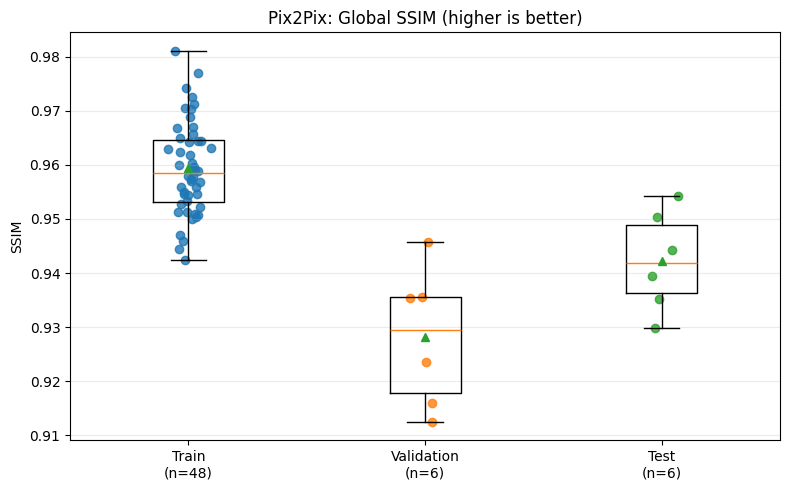

/tmp/ipykernel_47/1744756019.py:533: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


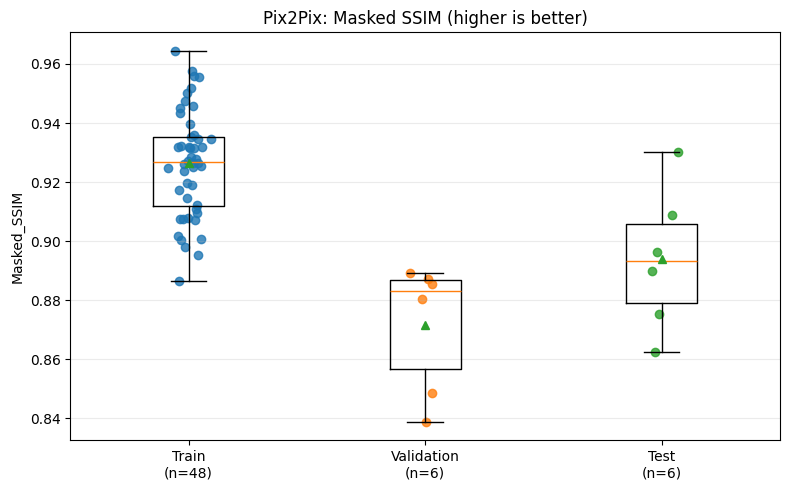

/tmp/ipykernel_47/1744756019.py:533: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


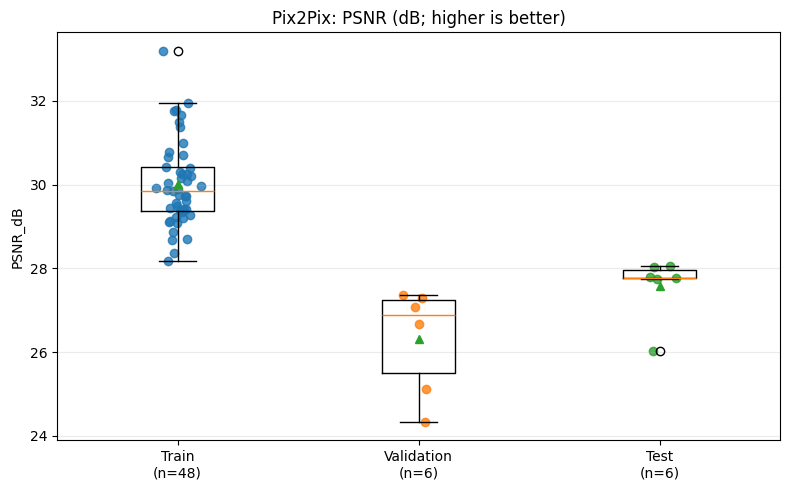

/tmp/ipykernel_47/1744756019.py:533: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


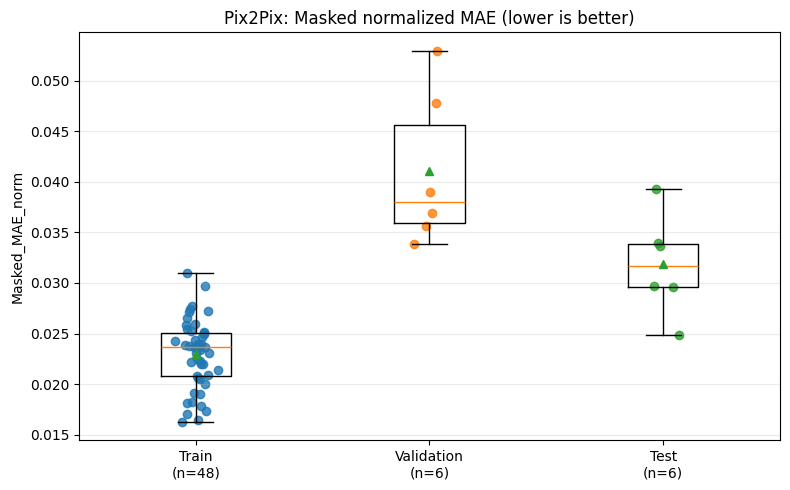

/tmp/ipykernel_47/1744756019.py:533: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


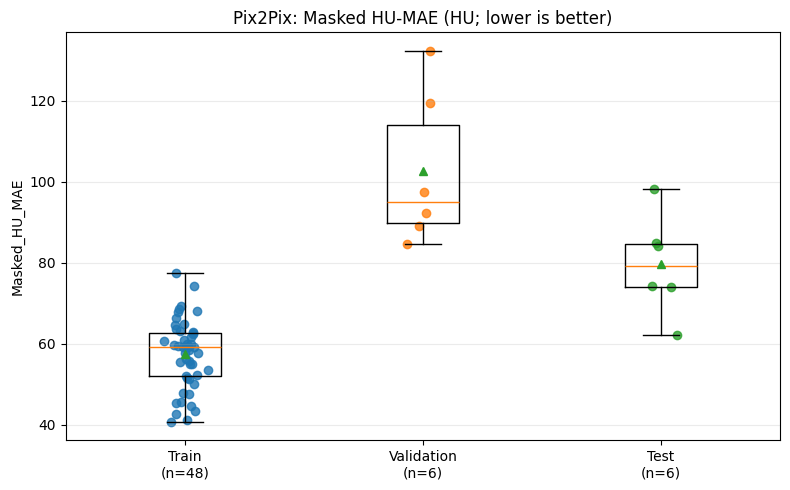

/tmp/ipykernel_47/1744756019.py:533: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


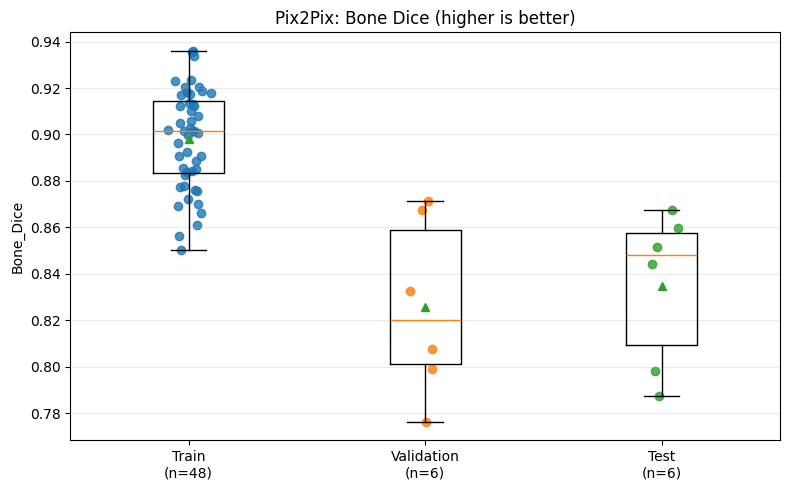

/tmp/ipykernel_47/1744756019.py:649: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.96])


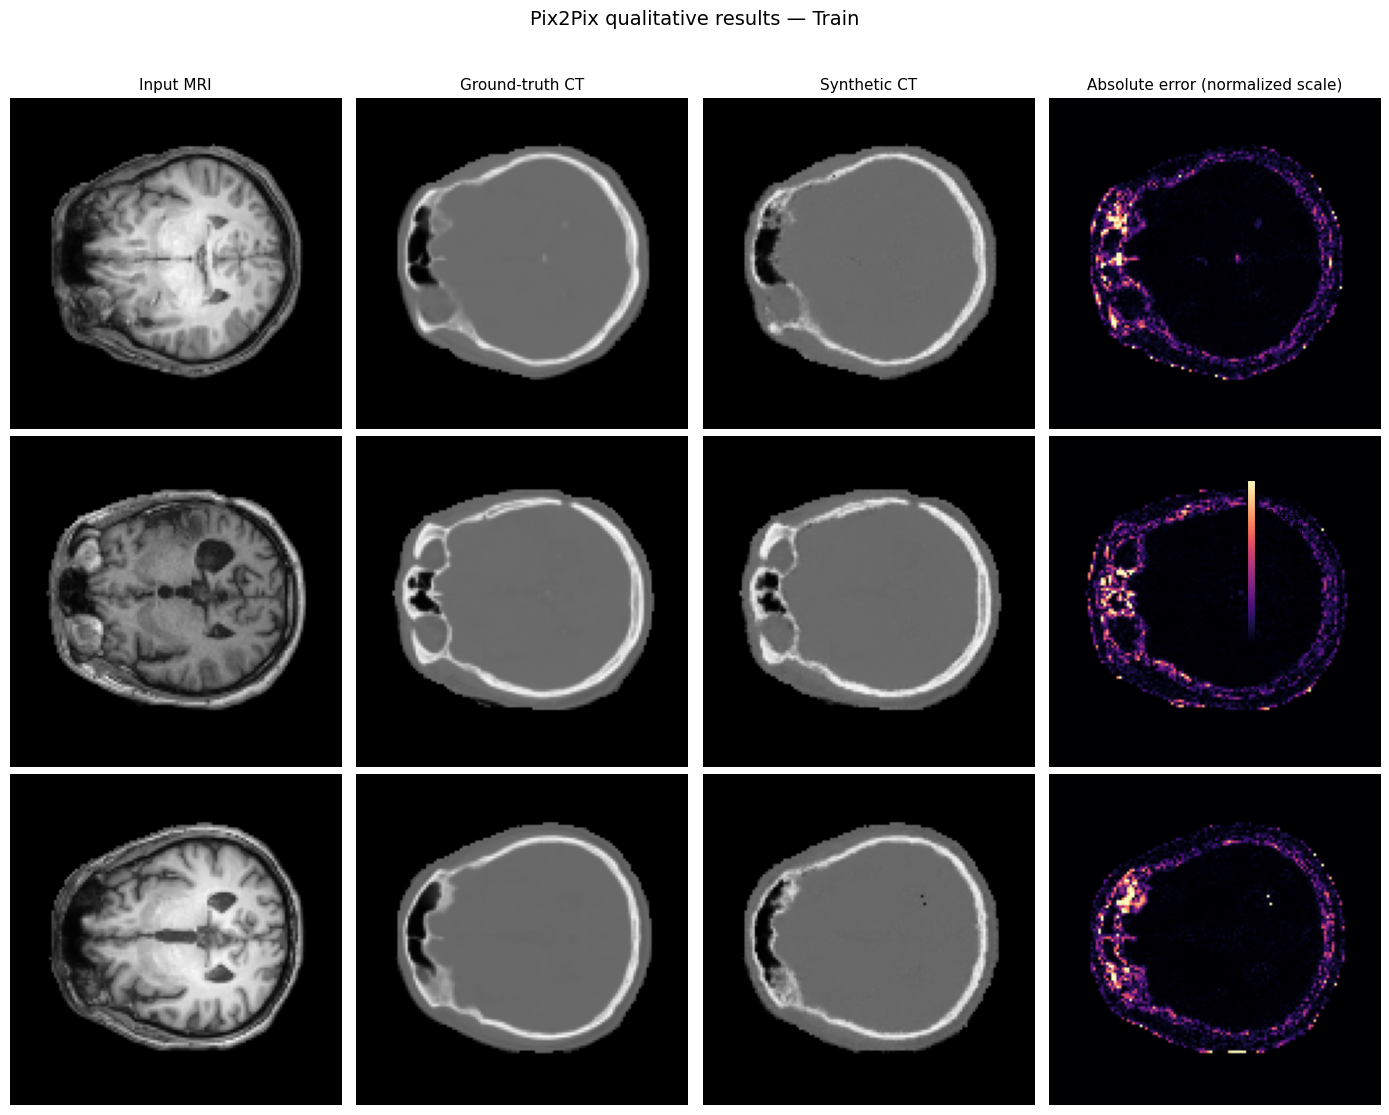

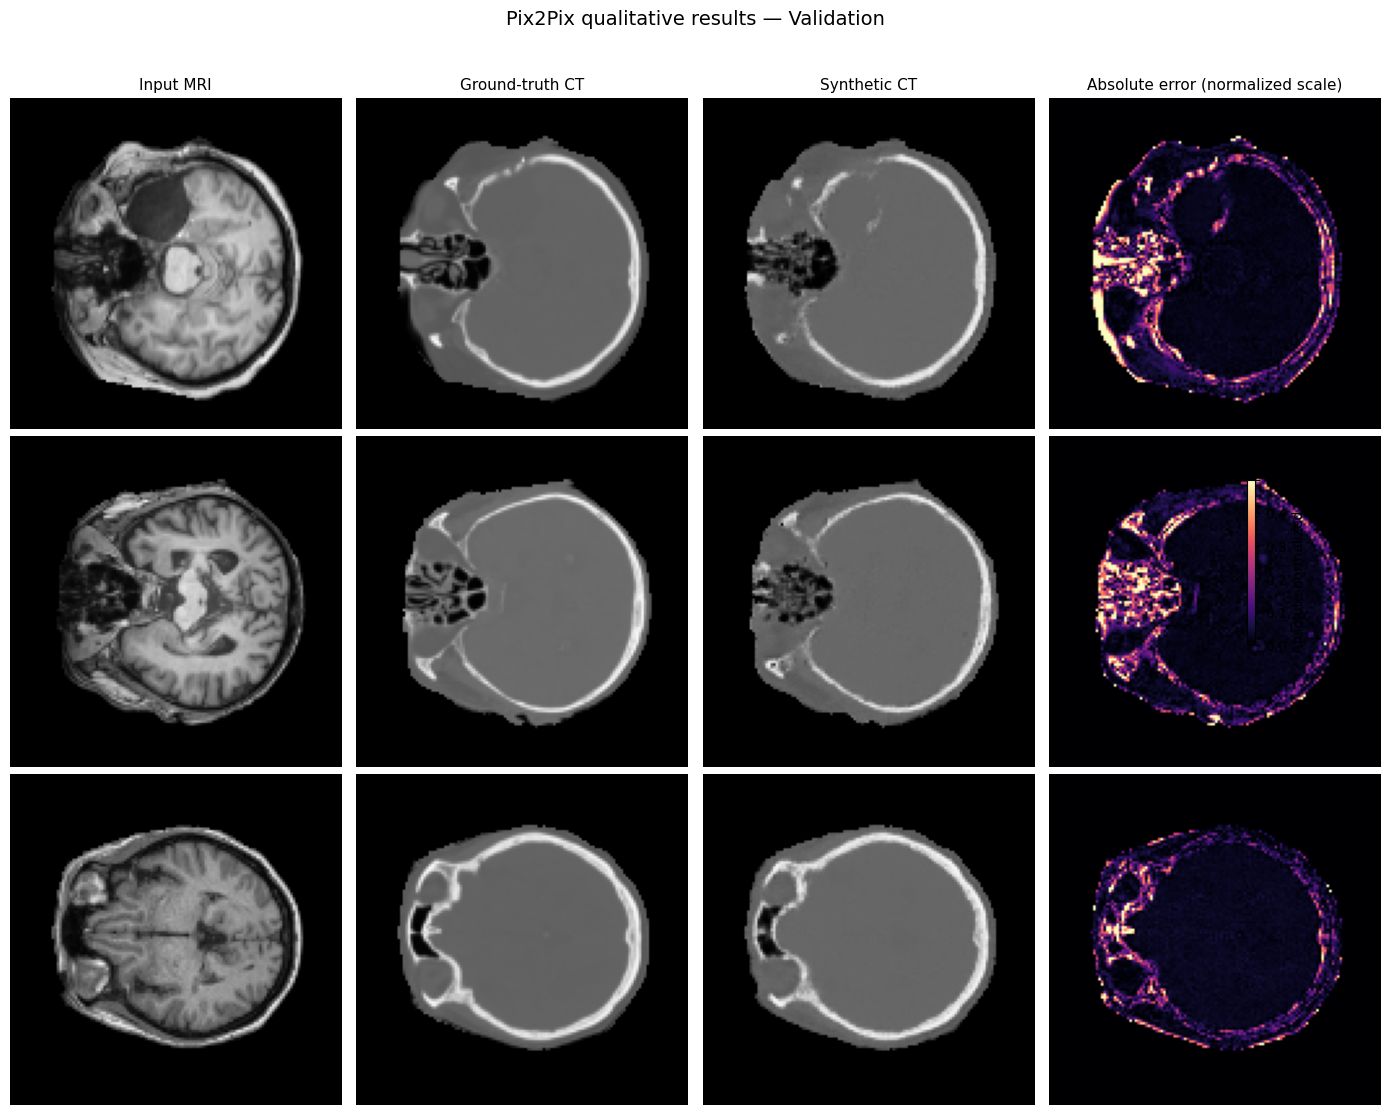

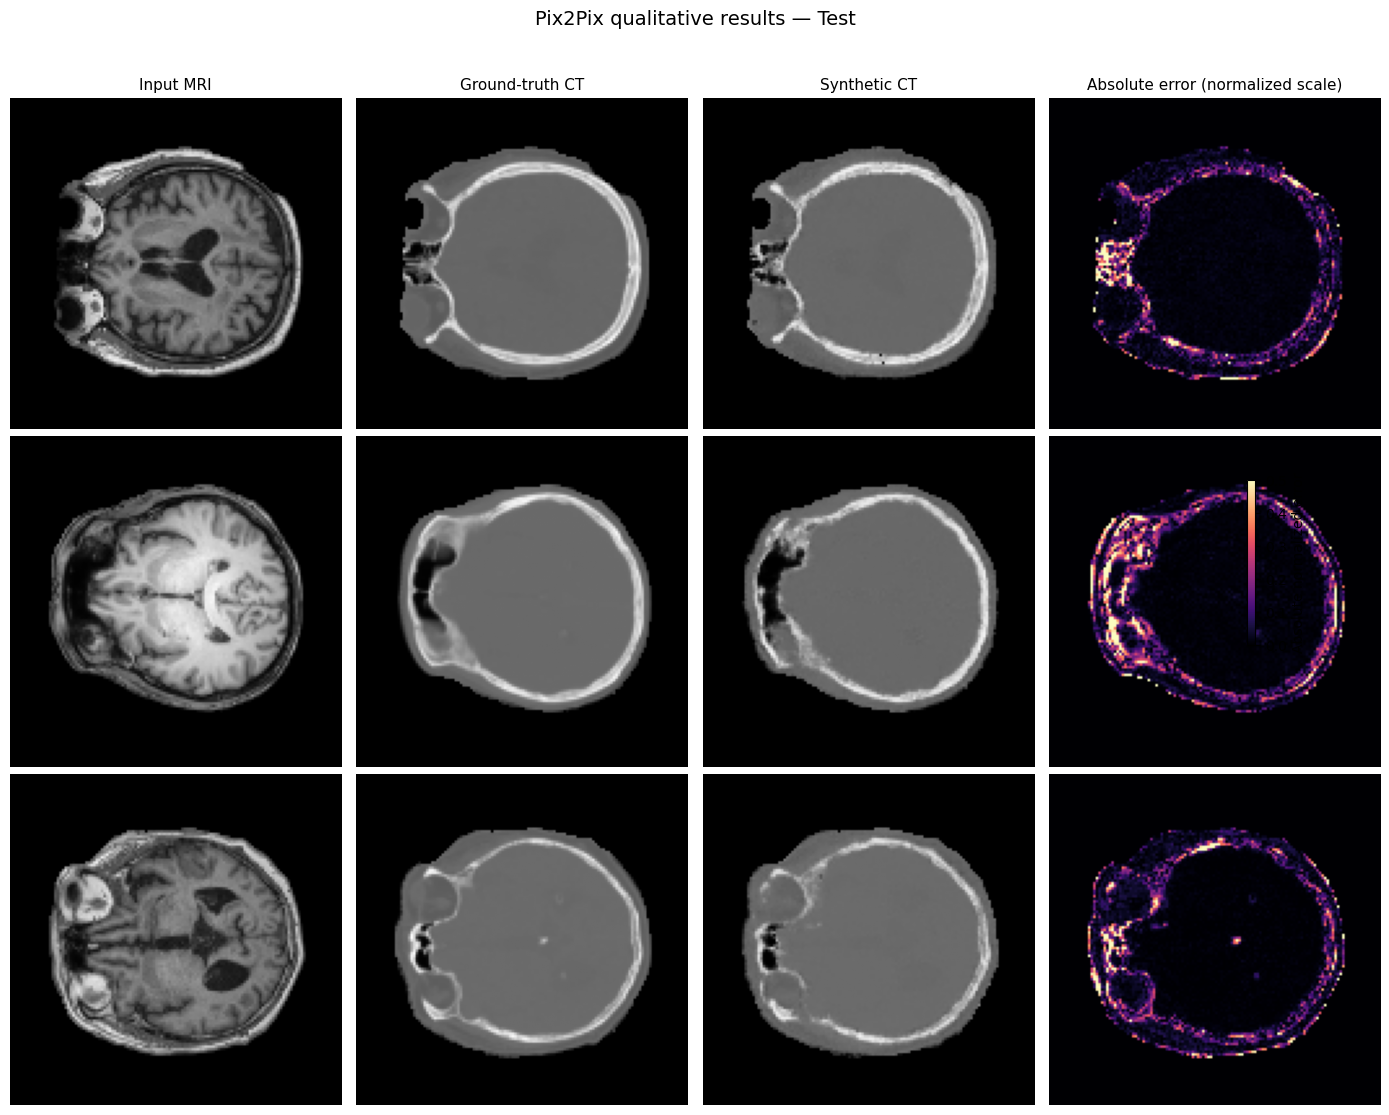


[PASS] All-split Pix2Pix evaluation and visualization completed.
Checkpoint: pix2pix_outputs/checkpoints/best_pix2pix_generator.pth
Train:      2879 slices
Validation: 372 slices
Test:       363 slices

CSV files:
  pix2pix_outputs/metrics/pix2pix_train_val_test_slice_metrics.csv
  pix2pix_outputs/metrics/pix2pix_train_val_test_patient_means.csv
  pix2pix_outputs/metrics/pix2pix_train_val_test_summary.csv

Visualization directory:
  pix2pix_outputs/train_val_test_visualizations


In [10]:

# =====================================================================
# CELL 10: EVALUATE AND VISUALIZE TRAIN / VALIDATION / TEST
# MODEL 2 — PIX2PIX
#
# Uses the best frozen generator checkpoint.
# No retraining, optimizer updates, or test-time optimization.
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# ---------------------------------------------------------------------
# 1. Verify notebook setup
# ---------------------------------------------------------------------
required = ["net_G", "device", "VERIFIED_SPLIT", "evaluate_slice"]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables/functions: {missing}. "
        "Run the model setup and evaluator cells first."
    )

if "train_dataset" not in globals():
    raise RuntimeError("train_dataset is not defined.")

if "test_dataset" not in globals():
    raise RuntimeError("test_dataset is not defined.")

if "val_dataset" in globals():
    val_ds = globals()["val_dataset"]
elif "validation_dataset" in globals():
    val_ds = globals()["validation_dataset"]
else:
    raise RuntimeError(
        "Could not find val_dataset or validation_dataset. "
        "Use the validation dataset variable defined in your notebook."
    )

split_datasets = {
    "Train": train_dataset,
    "Validation": val_ds,
    "Test": test_dataset,
}

if "train" not in VERIFIED_SPLIT or "test" not in VERIFIED_SPLIT:
    raise ValueError("VERIFIED_SPLIT must define train and test patient IDs.")

val_ids = VERIFIED_SPLIT.get(
    "val", VERIFIED_SPLIT.get("validation")
)
if val_ids is None:
    raise ValueError(
        "VERIFIED_SPLIT must define validation IDs under 'val' or 'validation'."
    )

expected_ids = {
    "Train": [str(p) for p in VERIFIED_SPLIT["train"]],
    "Validation": [str(p) for p in val_ids],
    "Test": [str(p) for p in VERIFIED_SPLIT["test"]],
}

# Verify that patients do not overlap across the three splits.
for a, b in [("Train", "Validation"),
             ("Train", "Test"),
             ("Validation", "Test")]:
    overlap = set(expected_ids[a]) & set(expected_ids[b])
    if overlap:
        raise ValueError(
            f"Patient overlap between {a} and {b}: {sorted(overlap)}"
        )

print("=" * 80)
print("PIX2PIX — TRAIN / VALIDATION / TEST EVALUATION")
for split_name, dataset in split_datasets.items():
    print(
        f"{split_name:12s}: "
        f"{len(expected_ids[split_name])} patients | "
        f"{len(dataset)} slices"
    )
print("=" * 80)

# ---------------------------------------------------------------------
# 2. Find and load the best generator checkpoint
# ---------------------------------------------------------------------
checkpoint_candidates = [
    Path("pix2pix_outputs/checkpoints/best_pix2pix_generator.pth"),
    Path("/kaggle/working/pix2pix_outputs/checkpoints/"
         "best_pix2pix_generator.pth"),
]

checkpoint_path = next(
    (path for path in checkpoint_candidates if path.is_file()),
    None,
)

if checkpoint_path is None:
    raise FileNotFoundError(
        "Best Pix2Pix checkpoint not found. Checked:\n"
        + "\n".join(str(p) for p in checkpoint_candidates)
    )

checkpoint = torch.load(checkpoint_path, map_location=device)

# Accept a raw state_dict or common checkpoint dictionary formats.
if isinstance(checkpoint, dict):
    for key in (
        "generator_state_dict",
        "net_G_state_dict",
        "model_state_dict",
        "state_dict",
        "generator",
        "net_G",
        "netG",
        "model",
    ):
        if key in checkpoint:
            candidate = checkpoint[key]

            if isinstance(candidate, torch.nn.Module):
                checkpoint = candidate.state_dict()
                break

            if isinstance(candidate, dict):
                checkpoint = candidate
                break

if isinstance(checkpoint, torch.nn.Module):
    checkpoint = checkpoint.state_dict()

if not isinstance(checkpoint, dict):
    raise TypeError("Unrecognized generator checkpoint format.")

if checkpoint and all(k.startswith("module.") for k in checkpoint):
    checkpoint = {
        k[len("module."):]: value
        for k, value in checkpoint.items()
    }

net_G.load_state_dict(checkpoint, strict=True)
net_G = net_G.to(device)
net_G.eval()

print(f"[OK] Loaded best generator: {checkpoint_path}")
print("[OK] Generator is in evaluation mode.")

# ---------------------------------------------------------------------
# 3. Disable common augmentation switches during evaluation.
#
# Training-set metrics must be calculated on unaugmented images.
# The code checks the dataset and common wrapper datasets.
# ---------------------------------------------------------------------
def walk_datasets(dataset, visited=None):
    if visited is None:
        visited = set()

    if id(dataset) in visited:
        return

    visited.add(id(dataset))
    yield dataset

    child = getattr(dataset, "dataset", None)
    if child is not None and child is not dataset:
        yield from walk_datasets(child, visited)

    children = getattr(dataset, "datasets", None)
    if children is not None:
        for child_dataset in children:
            yield from walk_datasets(child_dataset, visited)


augmentation_attributes = (
    "augment",
    "use_augmentation",
    "apply_augmentation",
    "training",
    "is_train",
    "train_mode",
)

original_flags = []
seen_attributes = set()
train_augmentation_flag_found = False

for split_name, dataset in split_datasets.items():
    for base_dataset in walk_datasets(dataset):
        for attr in augmentation_attributes:
            if not hasattr(base_dataset, attr):
                continue

            old_value = getattr(base_dataset, attr)

            if not isinstance(old_value, (bool, np.bool_)):
                continue

            if split_name == "Train":
                train_augmentation_flag_found = True

            key = (id(base_dataset), attr)
            if key in seen_attributes:
                continue

            seen_attributes.add(key)
            original_flags.append((base_dataset, attr, old_value))
            setattr(base_dataset, attr, False)

if train_augmentation_flag_found:
    print("[OK] Common boolean augmentation/training flags disabled.")
else:
    print(
        "[WARNING] No recognized augmentation flag was found in the "
        "training dataset. Before interpreting train metrics, verify that "
        "train_dataset does not apply random augmentation during __getitem__."
    )

# ---------------------------------------------------------------------
# 4. Evaluate all three splits
# ---------------------------------------------------------------------
required_metrics = [
    "SSIM",
    "Masked_SSIM",
    "PSNR_dB",
    "MAE_norm",
    "Masked_MAE_norm",
    "Masked_HU_MAE",
    "HU_MAE",
    "Bone_Dice",
]

records = []
qualitative_examples = {name: {} for name in split_datasets}

try:
    for split_name, dataset in split_datasets.items():

        loader = DataLoader(
            dataset,
            batch_size=8,
            shuffle=False,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )

        print(f"\nEvaluating {split_name}: {len(dataset)} slices")

        with torch.inference_mode():
            for batch in tqdm(loader, desc=f"{split_name} evaluation"):

                mri = batch["mri"].to(device, non_blocking=True)
                ct = batch["ct"].to(device, non_blocking=True)
                mask = batch["mask"].to(device, non_blocking=True)

                patient_ids = batch["patient_id"]
                slice_names = batch["slice_name"]

                pred = net_G(mri)

                if pred.shape != ct.shape:
                    raise ValueError(
                        f"{split_name}: generator output shape "
                        f"{tuple(pred.shape)} differs from CT shape "
                        f"{tuple(ct.shape)}."
                    )

                # Consistent MRI-derived mask post-processing.
                pred = torch.where(
                    mask > 0.5,
                    pred,
                    torch.full_like(pred, -1.0),
                )

                pred_np = pred[:, 0].cpu().numpy()
                ct_np = ct[:, 0].cpu().numpy()
                mri_np = mri[:, 0].cpu().numpy()
                mask_np = mask[:, 0].cpu().numpy()

                for i in range(len(patient_ids)):
                    pid = str(patient_ids[i])
                    slice_name = str(slice_names[i])

                    if pid not in set(expected_ids[split_name]):
                        raise AssertionError(
                            f"Unexpected patient {pid} in {split_name}."
                        )

                    metrics = dict(
                        evaluate_slice(
                            pred_np[i],
                            ct_np[i],
                            mask_np[i],
                        )
                    )

                    missing = [
                        metric for metric in required_metrics
                        if metric not in metrics
                    ]
                    if missing:
                        raise KeyError(
                            f"evaluate_slice() is missing {missing}. "
                            f"Returned keys: {list(metrics)}"
                        )

                    row = {
                        "Split": split_name,
                        "patient_id": pid,
                        "slice_name": slice_name,
                    }
                    row.update(metrics)
                    records.append(row)

                    # Retain only the slice with the largest MRI body
                    # mask per patient for useful qualitative examples.
                    # This avoids keeping all image arrays in memory.
                    body_area = int(np.count_nonzero(mask_np[i] > 0.5))

                    old_example = qualitative_examples[split_name].get(pid)

                    if old_example is None or body_area > old_example["body_area"]:
                        qualitative_examples[split_name][pid] = {
                            "body_area": body_area,
                            "slice_name": slice_name,
                            "mri": mri_np[i].copy(),
                            "ct": ct_np[i].copy(),
                            "pred": pred_np[i].copy(),
                            "mask": mask_np[i].copy(),
                        }

finally:
    # Restore the original dataset settings after evaluation.
    for dataset, attr, old_value in original_flags:
        setattr(dataset, attr, old_value)

# ---------------------------------------------------------------------
# 5. Check slice counts, patient coverage, and metric integrity
# ---------------------------------------------------------------------
df_all = pd.DataFrame(records)

if df_all.empty:
    raise RuntimeError("No samples were evaluated.")

if df_all.duplicated(
    subset=["Split", "patient_id", "slice_name"]
).any():
    raise AssertionError("Duplicate patient/slice records detected.")

for split_name, dataset in split_datasets.items():
    part = df_all[df_all["Split"] == split_name]

    if len(part) != len(dataset):
        raise AssertionError(
            f"{split_name}: expected {len(dataset)} slices, "
            f"evaluated {len(part)}."
        )

    observed = set(part["patient_id"])
    expected = set(expected_ids[split_name])

    if observed != expected:
        raise AssertionError(
            f"{split_name} patient coverage mismatch. "
            f"Missing={sorted(expected - observed)}; "
            f"unexpected={sorted(observed - expected)}"
        )

for metric in required_metrics:
    df_all[metric] = pd.to_numeric(df_all[metric], errors="coerce")

    if not np.isfinite(df_all[metric].to_numpy(dtype=float)).all():
        raise ValueError(
            f"{metric} contains NaN, Inf, or non-numeric values."
        )

# Include HD95 only when it is present and finite for every evaluated slice.
valid_metrics = list(required_metrics)

if "Bone_HD95_px" in df_all.columns:
    df_all["Bone_HD95_px"] = pd.to_numeric(
        df_all["Bone_HD95_px"], errors="coerce"
    )

    if np.isfinite(
        df_all["Bone_HD95_px"].to_numpy(dtype=float)
    ).all():
        valid_metrics.append("Bone_HD95_px")
    else:
        print(
            "[WARNING] HD95 is incomplete or non-finite; "
            "it will be excluded from summaries and plots."
        )

# ---------------------------------------------------------------------
# 6. Save all-split slice metrics
# ---------------------------------------------------------------------
output_root = checkpoint_path.parent.parent
metrics_dir = output_root / "metrics"
visual_dir = output_root / "train_val_test_visualizations"
metrics_dir.mkdir(parents=True, exist_ok=True)
visual_dir.mkdir(parents=True, exist_ok=True)

slice_csv = metrics_dir / "pix2pix_train_val_test_slice_metrics.csv"
df_all.to_csv(slice_csv, index=False)

# ---------------------------------------------------------------------
# 7. Calculate per-patient means
# ---------------------------------------------------------------------
patient_rows = []

for split_name in ("Train", "Validation", "Test"):
    split_df = df_all[df_all["Split"] == split_name]

    # Preserve the expected patient order.
    for pid in expected_ids[split_name]:
        patient_df = split_df[split_df["patient_id"] == pid]

        if patient_df.empty:
            raise AssertionError(
                f"No evaluated samples for {split_name} patient {pid}."
            )

        row = {
            "Split": split_name,
            "Patient ID": pid,
            "Slices": int(len(patient_df)),
        }

        for metric in valid_metrics:
            row[metric] = float(patient_df[metric].mean())

        patient_rows.append(row)

df_patient = pd.DataFrame(patient_rows)

patient_csv = metrics_dir / "pix2pix_train_val_test_patient_means.csv"
df_patient.to_csv(patient_csv, index=False)

# ---------------------------------------------------------------------
# 8. Primary summary: mean and SD across patient-level means
# ---------------------------------------------------------------------
metric_labels = {
    "SSIM": "Global SSIM (higher is better)",
    "Masked_SSIM": "Masked SSIM (higher is better)",
    "PSNR_dB": "PSNR (dB; higher is better)",
    "MAE_norm": "Normalized MAE (lower is better)",
    "Masked_MAE_norm": "Masked normalized MAE (lower is better)",
    "Masked_HU_MAE": "Masked HU-MAE (HU; lower is better)",
    "HU_MAE": "Global HU-MAE (HU; lower is better)",
    "Bone_Dice": "Bone Dice (higher is better)",
    "Bone_HD95_px": "Bone HD95 (pixels; lower is better)",
}

summary_rows = []

for split_name in ("Train", "Validation", "Test"):
    patient_subset = df_patient[df_patient["Split"] == split_name]

    for metric in valid_metrics:
        values = patient_subset[metric].to_numpy(dtype=float)

        mean_value = float(np.mean(values))
        sd_value = (
            float(np.std(values, ddof=1))
            if len(values) > 1 else np.nan
        )

        summary_rows.append({
            "Split": split_name,
            "Patients": int(len(patient_subset)),
            "Slices": int(
                df_all[df_all["Split"] == split_name].shape[0]
            ),
            "Metric": metric,
            "Metric description": metric_labels.get(metric, metric),
            "Mean across patient means": mean_value,
            "SD across patient means": sd_value,
            "Mean ± SD": f"{mean_value:.4f} ± {sd_value:.4f}",
        })

df_summary = pd.DataFrame(summary_rows)

summary_csv = metrics_dir / "pix2pix_train_val_test_summary.csv"
df_summary.to_csv(summary_csv, index=False)

print("\n" + "=" * 100)
print("PIX2PIX — PATIENT-LEVEL TRAIN / VALIDATION / TEST SUMMARY")
print("Mean ± sample SD across patient-level metric means")
print("=" * 100)

for split_name in ("Train", "Validation", "Test"):
    print(f"\n--- {split_name.upper()} ---")
    display_df = df_summary[df_summary["Split"] == split_name]
    print(
        display_df[["Metric description", "Mean ± SD"]]
        .to_string(index=False)
    )

# ---------------------------------------------------------------------
# 9. Visualize quantitative metric distributions across splits
#    Each point represents one patient, not one image slice.
# ---------------------------------------------------------------------
comparison_metrics = [
    "SSIM",
    "Masked_SSIM",
    "PSNR_dB",
    "Masked_MAE_norm",
    "Masked_HU_MAE",
    "Bone_Dice",
]

for metric in comparison_metrics:
    if metric not in df_patient.columns:
        continue

    groups = []
    labels = []

    for split_name in ("Train", "Validation", "Test"):
        values = df_patient.loc[
            df_patient["Split"] == split_name, metric
        ].dropna().to_numpy(dtype=float)

        groups.append(values)
        labels.append(f"{split_name}\n(n={len(values)})")

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.boxplot(
        groups,
        labels=labels,
        showmeans=True,
    )

    # Show individual patient means on top of each boxplot.
    rng = np.random.default_rng(42)

    for position, values in enumerate(groups, start=1):
        jitter = rng.normal(0, 0.045, size=len(values))
        ax.scatter(
            np.full(len(values), position) + jitter,
            values,
            alpha=0.8,
        )

    ax.set_title(f"Pix2Pix: {metric_labels.get(metric, metric)}")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    plot_path = visual_dir / f"metric_comparison_{metric}.png"
    fig.savefig(plot_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ---------------------------------------------------------------------
# 10. Qualitative visualization:
#     MRI input | Ground-truth CT | Synthetic CT | Absolute error
#
# One high-mask-area slice is selected per patient. This tends to
# produce more informative anatomical slices than the first slice.
# ---------------------------------------------------------------------
for split_name in ("Train", "Validation", "Test"):

    available_ids = [
        pid for pid in expected_ids[split_name]
        if pid in qualitative_examples[split_name]
    ]

    # Display up to three patients per split. All patients remain in CSVs.
    chosen_ids = available_ids[:3]

    if not chosen_ids:
        print(f"[WARNING] No qualitative examples found for {split_name}.")
        continue

    fig, axes = plt.subplots(
        nrows=len(chosen_ids),
        ncols=4,
        figsize=(14, 3.8 * len(chosen_ids)),
        squeeze=False,
    )

    column_titles = [
        "Input MRI",
        "Ground-truth CT",
        "Synthetic CT",
        "Absolute error (normalized scale)",
    ]

    for col, title in enumerate(column_titles):
        axes[0, col].set_title(title, fontsize=11)

    last_error_image = None

    for row_idx, pid in enumerate(chosen_ids):
        item = qualitative_examples[split_name][pid]

        # Images are normalized to [-1, 1]; display in [0, 1].
        mri_img = np.clip((item["mri"] + 1.0) / 2.0, 0.0, 1.0)
        ct_img = np.clip((item["ct"] + 1.0) / 2.0, 0.0, 1.0)
        pred_img = np.clip((item["pred"] + 1.0) / 2.0, 0.0, 1.0)

        abs_error = np.abs(item["pred"] - item["ct"])
        abs_error[item["mask"] <= 0.5] = 0.0

        images = [mri_img, ct_img, pred_img]

        for col_idx, image_array in enumerate(images):
            axes[row_idx, col_idx].imshow(
                image_array,
                cmap="gray",
                vmin=0,
                vmax=1,
            )
            axes[row_idx, col_idx].axis("off")

        last_error_image = axes[row_idx, 3].imshow(
            abs_error,
            cmap="magma",
            vmin=0,
            vmax=0.5,
        )
        axes[row_idx, 3].axis("off")

        axes[row_idx, 0].set_ylabel(
            f"{pid}\n{item['slice_name']}",
            fontsize=9,
        )

    # Shared error-map scale for the displayed samples.
    if last_error_image is not None:
        fig.colorbar(
            last_error_image,
            ax=axes[:, 3].tolist(),
            fraction=0.035,
            pad=0.02,
            label="Absolute normalized error",
        )

    fig.suptitle(
        f"Pix2Pix qualitative results — {split_name}",
        fontsize=14,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])

    figure_path = visual_dir / f"qualitative_{split_name.lower()}.png"
    fig.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ---------------------------------------------------------------------
# 11. Final completion report
# ---------------------------------------------------------------------
print("\n" + "=" * 90)
print("[PASS] All-split Pix2Pix evaluation and visualization completed.")
print(f"Checkpoint: {checkpoint_path}")
print(f"Train:      {len(df_all[df_all['Split'] == 'Train'])} slices")
print(f"Validation: {len(df_all[df_all['Split'] == 'Validation'])} slices")
print(f"Test:       {len(df_all[df_all['Split'] == 'Test'])} slices")

print("\nCSV files:")
print(f"  {slice_csv}")
print(f"  {patient_csv}")
print(f"  {summary_csv}")

print("\nVisualization directory:")
print(f"  {visual_dir}")
print("=" * 90)


In [11]:

# =====================================================================
# CELL 12: PACKAGE AND VERIFY MODEL 2 DELIVERABLES
# =====================================================================

import os
import zipfile
from pathlib import Path

WORKING_DIR = Path("/kaggle/working")
OUTPUT_DIR = WORKING_DIR / "pix2pix_outputs"
ZIP_PATH = WORKING_DIR / "synthrad_model2_pix2pix_deliverables.zip"

if not OUTPUT_DIR.is_dir():
    raise FileNotFoundError(
        f"Pix2Pix output directory not found: {OUTPUT_DIR}"
    )

files_to_package = sorted(
    path for path in OUTPUT_DIR.rglob("*")
    if path.is_file()
)

if not files_to_package:
    raise RuntimeError(
        f"No output files were found in {OUTPUT_DIR}"
    )

print("=" * 80)
print("PACKAGING MODEL 2: PIX2PIX")
print(f"Source directory: {OUTPUT_DIR}")
print(f"Files to package: {len(files_to_package)}")
print("=" * 80)

# Package all files while preserving their relative directory structure.
with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as zipf:
    for file_path in files_to_package:
        archive_name = file_path.relative_to(OUTPUT_DIR)
        zipf.write(file_path, arcname=str(archive_name))

# Verify ZIP integrity.
with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
    bad_file = zipf.testzip()
    archived_files = zipf.namelist()

if bad_file is not None:
    raise RuntimeError(f"ZIP integrity check failed on: {bad_file}")

if len(archived_files) != len(files_to_package):
    raise AssertionError(
        f"Expected {len(files_to_package)} files, "
        f"but archived {len(archived_files)}."
    )

# Verify that the best checkpoint has actually been packaged.
checkpoint_relative_path = Path(
    "checkpoints/best_pix2pix_generator.pth"
)

if not (OUTPUT_DIR / checkpoint_relative_path).is_file():
    raise FileNotFoundError(
        "The best Pix2Pix generator checkpoint is missing "
        "from pix2pix_outputs/checkpoints."
    )

if str(checkpoint_relative_path) not in archived_files:
    raise AssertionError(
        "Best generator checkpoint is missing from the ZIP archive."
    )

print("\n[PASS] ZIP integrity verification succeeded.")
print(f"ZIP file: {ZIP_PATH}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print(f"Archived files: {len(archived_files)}")

print("\nPackaged artifacts:")
for file_path in files_to_package:
    print(
        f"  {file_path.relative_to(OUTPUT_DIR)} "
        f"({file_path.stat().st_size / 1024:.1f} KB)"
    )

print("\n[PASS] Model 2 artifacts packaged and verified.")
print("Locate the ZIP in the Kaggle /working output files.")
print("=" * 80)


PACKAGING MODEL 2: PIX2PIX
Source directory: /kaggle/working/pix2pix_outputs
Files to package: 25

[PASS] ZIP integrity verification succeeded.
ZIP file: /kaggle/working/synthrad_model2_pix2pix_deliverables.zip
ZIP size: 317.50 MB
Archived files: 25

Packaged artifacts:
  checkpoints/best_epoch_metadata.json (0.4 KB)
  checkpoints/best_pix2pix_discriminator.pth (10804.3 KB)
  checkpoints/best_pix2pix_generator.pth (163385.3 KB)
  checkpoints/final_pix2pix_discriminator.pth (10804.4 KB)
  checkpoints/final_pix2pix_generator.pth (163385.3 KB)
  configs/config.json (2.2 KB)
  configs/patient_split_seed42.json (1.0 KB)
  metrics/pix2pix_test_patient_metrics.csv (2.5 KB)
  metrics/pix2pix_test_slice_metrics.csv (83.5 KB)
  metrics/pix2pix_test_slice_weighted_summary.csv (0.7 KB)
  metrics/pix2pix_test_summary_metrics.csv (0.8 KB)
  metrics/pix2pix_train_val_test_patient_means.csv (11.1 KB)
  metrics/pix2pix_train_val_test_slice_metrics.csv (851.0 KB)
  metrics/pix2pix_train_val_test_summary